# **Ringkasan Eksekutif**
Alfamart merupakan jaringan ritel minimarket yang menyediakan berbagai kebutuhan sehari-hari melalui ribuan gerai di berbagai wilayah Indonesia. Dalam menjalankan strategi pemasaran dan meningkatkan daya tarik belanja pelanggan, Alfamart menyelenggarakan berbagai program promosi, salah satunya Promo JSM (Jumat, Sabtu, dan Minggu). Program ini menawarkan potongan harga untuk produk tertentu selama akhir pekan dengan tujuan menarik kunjungan pelanggan dan meningkatkan aktivitas transaksi.

Namun, terdapat indikasi potensi penyalahgunaan promo melalui pembelian produk dalam jumlah besar oleh sebagian kecil pembeli yang diduga bertujuan untuk dijual kembali (reselling).

Proyek ini bertujuan menganalisis data transaksi POS Alfamart untuk mengidentifikasi pola pembelian produk JSM, mendeteksi transaksi dengan kuantitas tidak biasa, serta mengestimasi potensi dampak finansial. Hasil analisis diharapkan dapat menjadi dasar rekomendasi kebijakan pembatasan kuantitas pembelian produk promo guna menjaga efektivitas promosi dan ketersediaan produk bagi konsumen akhir.

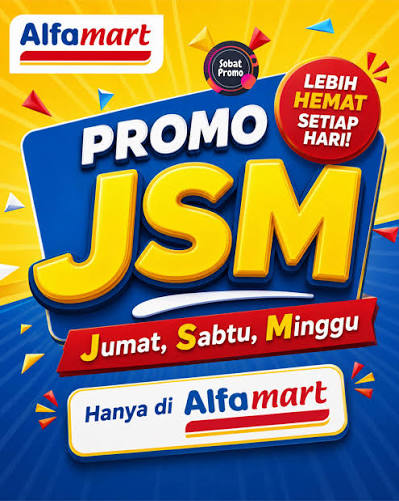

# **Daftar Isi**

1. **Ringkasan Eksekutif**
2. **Business Understanding**
   - Latar Belakang
   - Stakeholder
   - Rumusan Masalah & Tujuan Analisis
3. **Data Extract**
   - Extract Data from BigQuery
   - Data Dictionary
4. **Data Merging**
5. **Data Cleaning**
   - Data Format
   - Missing Values
   - Data Types
   - Data Duplicates
   - Data Range Constraints
   - Treatment Data Negatif
   - Outlier Detection
6. **Data Analysis**
   - Sales Overview & Trend
   - Product & Bulk Transaction Analysis
   - Candidate Purchase Limit using IQR
   - Restriction Scenario Simulation
   - Customer Behavior Analysis
   - Financial Impact Analysis
   - SKU Evaluation
   - Pemeriksaan Contoh Transaksi Ekstrem
   - Transaction Value Validation
   - Quantity Distribution by SKU and Unit
   - Store Impact Analysis
   - Customer-Level Restriction Policy Simulation
7. **Conclusion & Recommendations**


# **Business Understanding**

### **Latar Belakang**

Promo JSM (Jumat, Sabtu, dan Minggu) merupakan program promosi Alfamart yang menawarkan potongan harga untuk produk tertentu selama akhir pekan guna meningkatkan daya tarik belanja dan aktivitas penjualan.

Namun, promo harga khusus berpotensi mendorong pembelian produk dalam jumlah besar oleh sebagian pembeli, sehingga dapat mengurangi ketersediaan produk bagi pelanggan lain dan memengaruhi profitabilitas promosi.

Fenomena serupa pernah terjadi pada Januari 2022, ketika tingginya permintaan minyak goreng seharga Rp14.000 per liter menyebabkan stok di sejumlah gerai ritel cepat habis. Sebagai upaya pengendalian, Alfamart menerapkan batas pembelian maksimal 2 kemasan ukuran 1 liter dan 1 kemasan ukuran 2 liter per orang.

Peristiwa tersebut menjadi preseden penting untuk mengevaluasi pola pembelian dan kebutuhan pembatasan kuantitas pada produk Promo JSM.





### **Stakeholder**
Pihak-pihak yang berkepentingan dalam analisis ini meliputi:

* Manajemen Alfamart: membutuhkan informasi mengenai potensi dampak finansial dan rekomendasi kebijakan pengendalian pembelian produk promo.

* Tim Data Analyst: bertanggung jawab mengolah dan menganalisis data transaksi untuk mengidentifikasi pola pembelian serta menghasilkan insight berbasis data.

* Tim Operasional Gerai: membutuhkan rekomendasi yang dapat diterapkan dalam pengawasan transaksi dan pengelolaan ketersediaan produk promo.

* Pelanggan: menjadi pihak yang terdampak oleh kebijakan promosi, khususnya dalam hal ketersediaan dan kesempatan memperoleh produk promo.

### **Rumusan Masalah & Tujuan Analisis**
1. Identifikasi Dampak Finansial

    Mengestimasi besaran potensi kebocoran margin dari pola pembelian yang mengindikasikan penyalahgunaan Promo JSM.

2. Desain Kebijakan Pembatasan

    Merumuskan rekomendasi kebijakan pembatasan kuantitas pembelian per pelanggan untuk SKU promo JSM, dengan mengacu pada preseden pembatasan pembelian yang pernah diterapkan Alfamart pada kasus minyak goreng tahun 2022.

# **Data Extract**



### **Extract Data from BigQuery**

Tahap ini mencakup import library Python yang diperlukan untuk analisis, melakukan autentikasi akun Google ke Google Cloud, menghubungkan Google Colab dengan BigQuery, serta mengekstrak lima dataset Alfamart secara langsung dari BigQuery untuk proses eksplorasi dan pengolahan data selanjutnya.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_gbq
import missingno as msno

from google.cloud import bigquery
from google.colab import auth

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 1000)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [2]:
# BigQuery configurations
project_id = 'purwadhika-512314'
dataset_id = 'Capstone_3'

# Read data
tables = {
    "transactions": "alfa_pos_transactions",
    "products": "alfa_products",
    "stores": "alfa_stores",
    "members": "alfa_members",
    "complaints": "alfa_complaint_tickets"
}

data = {}

for table_name, table_id in tables.items():
    sql_query = f"""
    SELECT *
    FROM `{project_id}.{dataset_id}.{table_id}`
    """

    data[table_name] = pandas_gbq.read_gbq(
        sql_query,
        project_id=project_id
    )

for table_name, df in data.items():
  print(f"\nDataset: {table_name}")
  print(f"Jumlah baris : {df.shape[0]:,}")
  print(f"Jumlah kolom : {df.shape[1]}")

Downloading: 100%|██████████|
Downloading: 100%|██████████|
Downloading: 100%|██████████|
Downloading: 100%|██████████|
Downloading: 100%|██████████|

Dataset: transactions
Jumlah baris : 455,148
Jumlah kolom : 12

Dataset: products
Jumlah baris : 507
Jumlah kolom : 11

Dataset: stores
Jumlah baris : 1,003
Jumlah kolom : 10

Dataset: members
Jumlah baris : 48,214
Jumlah kolom : 10

Dataset: complaints
Jumlah baris : 10,759
Jumlah kolom : 9


In [3]:
# Mengakses dataset dari dictionary
df_transactions = data['transactions']
df_products = data['products']
df_stores = data['stores']
df_members = data['members']
df_complaints = data['complaints']

# Menggabungkan dataset ke dalam dictionary
datasets = {
    "Transactions": df_transactions,
    "Products": df_products,
    "Stores": df_stores,
    "Members": df_members,
    "Complaints": df_complaints
}

# Menampilkan informasi setiap dataset
for name, df in datasets.items():

    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    print("Jumlah baris  :", df.shape[0])
    print("Jumlah kolom  :", df.shape[1])
    print("Ukuran dataset:", df.shape)

    display(df.head())


DATASET: TRANSACTIONS
Jumlah baris  : 455148
Jumlah kolom  : 12
Ukuran dataset: (455148, 12)


,receipt_id,store_id,sku_id,member_id,trx_time,payment_method,qty,total_price,transaction_status,discount_amount,points_earned,checkout_channel
0,RCP00129083,SAT-0039,SKU000001,MEM-18001,2023-05-02 13:00:00+00:00,CASH,-5,"-60,500.00",COMPLETED,0.00,0,Kasir Reguler
1,RCP00058071,SAT-0180,SKU000001,MEM-09380,2024-09-27 08:00:00+00:00,debit bca,-7,"-58,443.00",COMPLETED,"-26,257.00",0,Kasir Reguler
2,RCP00121686,SAT-0169,SKU000001,MEM-13358,2023-11-02 21:00:00+00:00,Gopay,-2,"-24,200.00",COMPLETED,0.00,0,Kasir Reguler
3,RCP00001532,SAT-0843,SKU000001,None,2023-04-01 20:00:00+00:00,Cash,1,"8,349.00",COMPLETED,"3,751.00",0,Kasir Reguler
4,RCP00001555,SAT-0851,SKU000001,MEM-39956,2023-09-09 10:00:00+00:00,CASH,1,"8,349.00",COMPLETED,"3,751.00",1,Kasir Reguler



DATASET: PRODUCTS
Jumlah baris  : 507
Jumlah kolom  : 11
Ukuran dataset: (507, 11)


,sku_id,product_name,category,brand,unit_price,unit_of_measure,is_perishable,shelf_life_days,supplier_id,is_jsm_promo,jsm_discount_pct
0,SKU000020,AQ btl 600,Beverage,Danone-Aqua,"17,900.00",botol,0,509,SUP-177,0,0.00
1,SKU000080,AQ btl 600,Beverage,Danone-Aqua,"9,300.00",botol,1,33,SUP-121,0,0.00
2,SKU000082,AQ btl 600,Beverage,Danone-Aqua,"18,600.00",botol,0,302,SUP-163,0,0.00
3,SKU000108,AQ btl 600,Beverage,Danone-Aqua,"6,000.00",botol,0,400,SUP-110,0,0.00
4,SKU000125,AQ btl 600,Beverage,Danone-Aqua,"44,100.00",botol,0,682,SUP-197,0,0.00



DATASET: STORES
Jumlah baris  : 1003
Jumlah kolom  : 10
Ukuran dataset: (1003, 10)


,store_id,store_name,city,province,open_date,store_type,store_format,store_size_sqm,has_self_checkout,region_code
0,SAT-0291,Alfamart Sudirman 290,Tangerang,Banten,2021-05-31,Perkantoran,Besar (Reguler Plus),269,1,REG-BANTEN-1
1,SAT-0479,Alfamart Sudirman 478,Tangerang,Banten,2023-06-01,Residential/Perumahan,Besar (Reguler Plus),380,0,REG-BANTEN-1
2,SAT-0540,Alfamart Melati 539,Tangerang,Banten,2023-03-11,Perkantoran,Besar (Reguler Plus),392,0,REG-BANTEN-1
3,SAT-0912,Alfamart Pahlawan 911,Tangerang,Banten,2022-02-02,Perkantoran,Besar (Reguler Plus),297,0,REG-BANTEN-1
4,SAT-0158,Alfamart Pahlawan 157,Tangerang,Banten,2021-01-22,Residential/Perumahan,Besar (Reguler Plus),253,0,REG-BANTEN-2



DATASET: MEMBERS
Jumlah baris  : 48214
Jumlah kolom  : 10
Ukuran dataset: (48214, 10)


,member_id,registration_date,home_city,gender,birth_year,membership_tier,acquisition_channel,phone_verified,points_balance,last_active_date
0,MEM-00354,2022-05-17,Bandung,P,1965,Reguler,Aplikasi Alfagift,0,4079,2023-01-07
1,MEM-00360,2021-06-20,Bandung,P,1965,Reguler,Aplikasi Alfagift,1,10145,2022-12-16
2,MEM-00365,2021-09-17,Bandung,L,1965,Gold,Aplikasi Alfagift,0,20379,2022-02-24
3,MEM-00449,2021-04-20,Bandung,P,1965,Gold,Daftar di Toko,0,49777,2022-01-03
4,MEM-00575,2020-11-18,Bandung,L,1965,Reguler,Aplikasi Alfagift,1,24599,2021-12-02



DATASET: COMPLAINTS
Jumlah baris  : 10759
Jumlah kolom  : 9
Ukuran dataset: (10759, 9)


,ticket_id,receipt_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,disputed_amount
0,TCK0100151,RCP00011375,Antrian Lama,2021-05-22 21:00:00+00:00,Call Center 1500-959,Pending,NaN,NaN,"129,196.00"
1,TCK0100181,RCP00256185,Antrian Lama,2021-06-05 21:00:00+00:00,Aplikasi Alfagift,Pending,NaN,NaN,"26,834.00"
2,TCK0100208,RCP00389182,Antrian Lama,2021-06-17 03:00:00+00:00,Aplikasi Alfagift,Pending,NaN,NaN,"172,032.00"
3,TCK0100213,RCP00016275,Antrian Lama,2021-06-17 14:00:00+00:00,Langsung ke Gerai,Pending,NaN,NaN,"29,915.00"
4,TCK0100234,RCP00182445,Antrian Lama,2021-06-27 20:00:00+00:00,Aplikasi Alfagift,Pending,NaN,NaN,"12,282.00"


## Alfamart POS Transaction
Dataset `alfa_pos_transactions` terdiri atas **12 fitur** dengan total **455.148 records**. Dataset ini berisi catatan transaksi penjualan Alfamart, termasuk informasi produk, pelanggan, gerai, waktu transaksi, metode pembayaran, dan nilai transaksi.

| Feature | Description |
|---|---|
| receipt_id | ID struk transaksi sebagai identitas transaksi. |
| store_id | ID gerai Alfamart tempat transaksi dilakukan. |
| sku_id | ID unik produk atau Stock Keeping Unit (SKU). |
| member_id | ID pelanggan yang terdaftar sebagai member. |
| trx_time | Tanggal dan waktu ketika transaksi dilakukan. |
| payment_method | Metode pembayaran yang digunakan pelanggan. |
| qty | Jumlah unit produk yang dibeli. |
| total_price | Total nilai transaksi produk. |
| transaction_status | Status transaksi. |
| discount_amount | Jumlah potongan harga transaksi. |
| points_earned | Jumlah poin membership yang diperoleh. |
| checkout_channel | Kanal checkout yang digunakan dalam transaksi. |


## Alfamart Products

Dataset `alfa_products` terdiri atas **11 fitur** dengan total **507 records**. Dataset ini berisi informasi master produk Alfamart, termasuk nama produk, kategori, merek, harga, ukuran, supplier, serta informasi Promo JSM.

| Feature | Description |
|---|---|
| sku_id | ID unik setiap SKU produk. |
| product_name | Nama produk. |
| category | Kategori produk. |
| brand | Merek atau brand produk. |
| unit_price | Harga produk per unit. |
| unit_of_measure | Satuan pengukuran atau penjualan produk. |
| is_perishable | Indikator apakah produk termasuk barang yang mudah rusak atau memiliki masa simpan terbatas. |
| shelf_life_days | Masa simpan produk dalam satuan hari. |
| supplier_id | ID supplier atau pemasok produk. |
| is_jsm_promo | Indikator apakah SKU termasuk produk Promo JSM. |
| jsm_discount_pct | Persentase diskon yang terkait dengan Promo JSM. |


## Alfamart Stores

Dataset `alfa_stores` terdiri atas **10 fitur** dengan total **1.003 records**. Dataset ini berisi informasi master gerai Alfamart, termasuk lokasi, tanggal pembukaan, jenis gerai, format gerai, ukuran gerai, dan fasilitas yang tersedia.

| Feature | Description |
|---|---|
| store_id | ID unik setiap gerai Alfamart. |
| store_name | Nama gerai Alfamart. |
| city | Kota tempat gerai berada. |
| province | Provinsi tempat gerai berada. |
| open_date | Tanggal pertama kali gerai dibuka atau mulai beroperasi. |
| store_type | Jenis atau tipe gerai. |
| store_format | Format atau konsep operasional gerai. |
| store_size_sqm | Luas gerai dalam satuan meter persegi. |
| has_self_checkout | Indikator ketersediaan fasilitas self-checkout pada gerai. |
| region_code | Kode wilayah atau regional tempat gerai berada. |


## Alfamart Members

Dataset `alfa_members` terdiri atas **10 fitur** dengan total **48.214 records**. Dataset ini berisi informasi pelanggan yang terdaftar sebagai member Alfamart, termasuk data registrasi, karakteristik pelanggan, tingkat membership, dan aktivitas keanggotaan.

| Feature | Description |
|---|---|
| member_id | ID unik setiap pelanggan yang terdaftar sebagai member. |
| registration_date | Tanggal pelanggan pertama kali mendaftar sebagai member. |
| home_city | Kota tempat tinggal pelanggan berdasarkan data registrasi. |
| gender | Jenis kelamin pelanggan. |
| birth_year | Tahun kelahiran pelanggan. |
| membership_tier | Tingkatan atau kategori membership pelanggan. |
| acquisition_channel | Kanal yang digunakan pelanggan untuk bergabung menjadi member. |
| phone_verified | Indikator apakah nomor telepon pelanggan telah diverifikasi. |
| points_balance | Jumlah saldo poin membership yang dimiliki pelanggan. |
| last_active_date | Tanggal terakhir aktivitas pelanggan yang tercatat. |


## Alfamart Complaint Tickets

Dataset `alfa_complaint_tickets` terdiri atas **9 fitur** dengan total **10.759 records**. Dataset ini berisi informasi tiket komplain pelanggan yang berkaitan dengan transaksi Alfamart, termasuk kategori keluhan, kanal pengaduan, status penyelesaian, waktu penyelesaian, dan nilai transaksi yang dipermasalahkan.

| Feature | Description |
|---|---|
| ticket_id | ID unik setiap tiket komplain pelanggan. |
| receipt_id | ID struk transaksi yang berkaitan dengan komplain. |
| complaint_category | Kategori atau jenis keluhan yang disampaikan pelanggan. |
| ticket_date | Tanggal dan waktu tiket komplain dibuat. |
| channel | Kanal yang digunakan pelanggan untuk menyampaikan komplain. |
| resolution_status | Status penanganan atau penyelesaian komplain. |
| resolution_time_hours | Waktu yang dibutuhkan untuk menyelesaikan komplain dalam satuan jam. |
| csat_score | Customer Satisfaction Score atau skor kepuasan pelanggan terhadap penanganan komplain. |
| disputed_amount | Nilai uang yang dipermasalahkan dalam komplain pelanggan. |


# **Data Merging**
Tahap ini mencakup penggabungan lima dataset Alfamart, yaitu Transactions, Products, Stores, Members, dan Complaint Tickets berdasarkan kolom kunci yang saling berkaitan. Proses ini bertujuan mengintegrasikan informasi transaksi dengan data produk, gerai, pelanggan, dan komplain sehingga menghasilkan dataset yang lebih lengkap dan kontekstual untuk mendukung proses analisis.

In [4]:
# Menggabungkan Transactions dengan Products
df_merged = df_transactions.merge(
    df_products,
    on='sku_id',
    how='left',
    suffixes=('', '_product'),
    validate='many_to_one'
)

# Menggabungkan hasil dengan Stores
df_merged = df_merged.merge(
    df_stores,
    on='store_id',
    how='left',
    suffixes=('', '_store'),
    validate='many_to_one'
)

# Menggabungkan hasil dengan Members
df_merged = df_merged.merge(
    df_members,
    on='member_id',
    how='left',
    suffixes=('', '_member'),
    validate='many_to_one'
)

# Mengelompokkan Complaints berdasarkan receipt_id
df_complaints_summary = (
    df_complaints
    .groupby('receipt_id')
    .agg(
        complaint_count=('ticket_id', 'count'),
        complaint_category=(
            'complaint_category',
            lambda x: ', '.join(x.dropna().astype(str).unique())
        ),
        resolution_status=(
            'resolution_status',
            lambda x: ', '.join(x.dropna().astype(str).unique())
        ),
        avg_resolution_time=('resolution_time_hours', 'mean'),
        avg_csat_score=('csat_score', 'mean'),
        total_disputed_amount=('disputed_amount', 'sum')
    )
    .reset_index()
)

# Menggabungkan hasil dengan Complaint Summary
df_merged = df_merged.merge(
    df_complaints_summary,
    on='receipt_id',
    how='left',
    validate='many_to_one'
)


# **Data Cleaning**

### **Data Format**

Tahap ini mencakup pemeriksaan dan penyeragaman format penulisan pada setiap kolom untuk memastikan konsistensi data, terutama pada kolom yang berisi kategori dan informasi produk.

In [5]:
# Melihat unique value dan jumlahnya pada kolom payment_method
display(df_merged['payment_method'].value_counts())

# Melihat unique value dan jumlahnya pada kolom product_name
display(df_merged['product_name'].value_counts())

,count
payment_method,
Cash,90496
CASH,60523
BCA Debit,45779
Gopay,45704
Tunai,45664
ShopeePay,45224
qris,30593
OVO,30488
debit bca,30373


,count
product_name,
Pepsodent 190g,48350
ROKOK SAMPOERNA MILD,46707
Rokok Sampoerna Mild,42854
Mnyk Goreng Bimoli,41413
PEPSODENT 190G,40699
Air Mineral Aqua,37181
Indm Grg,32273
Bimoli Pouch 2000ml,32200
Minyak Bimoli 2L,29321


In [6]:
# Menyeragamkan penulisan metode pembayaran
df_merged['payment_method'] = df_merged['payment_method'].replace({
    'CASH': 'Cash',
    'debit bca': 'Debit BCA',
    'BCA Debit': 'Debit BCA',
    'qris': 'QRIS'
})


# Menyeragamkan penulisan metode pembayaran
df_merged['product_name'] = df_merged['product_name'].replace({
    'ROKOK SAMPOERNA MILD': 'Rokok Sampoerna Mild',
    'PEPSODENT 190G': 'Pepsodent 190g',
    'indomie goreng': 'Indomie Goreng',
    'INDOMIE MIE GORENG': 'Indomie Goreng',
    'Indm Grg': 'Indomie Goreng',
    'Mnyk Goreng Bimoli': 'Minyak Goreng Bimoli',
    'AQ btl 600': 'Aqua 600ml',
})

In [7]:
# Hasil unique value dan jumlahnya pada kolom payment_method
display(df_merged['payment_method'].value_counts())

# Hasil unique value dan jumlahnya pada kolom product_name
display(df_merged['product_name'].value_counts())

,count
payment_method,
Cash,151019
Debit BCA,76152
QRIS,60897
Gopay,45704
Tunai,45664
ShopeePay,45224
OVO,30488


,count
product_name,
Rokok Sampoerna Mild,89561
Pepsodent 190g,89049
Indomie Goreng,84835
Aqua 600ml,48705
Minyak Goreng Bimoli,41413
Air Mineral Aqua,37181
Bimoli Pouch 2000ml,32200
Minyak Bimoli 2L,29321
Mie Sedaap Goreng,590


In [8]:
# Memeriksa whitespace pada seluruh kolom bertipe teks
text_columns = df_merged.select_dtypes(include='object').columns

for col in text_columns:
    leading_trailing = df_merged[col].dropna().astype(str).apply(
        lambda x: x != x.strip()
    ).sum()

    whitespace_only = df_merged[col].dropna().astype(str).apply(
        lambda x: x.strip() == ''
    ).sum()

    if leading_trailing > 0 or whitespace_only > 0:
        print(f"\nKolom: {col}")
        print("Spasi di awal/akhir:", leading_trailing)
        print("Data hanya berisi spasi:", whitespace_only)



### **Missing Value**

Tahap ini mencakup identifikasi dan pemeriksaan nilai kosong pada setiap kolom, analisis penyebab missing values, serta penentuan metode penanganan yang sesuai tanpa menghilangkan informasi penting.

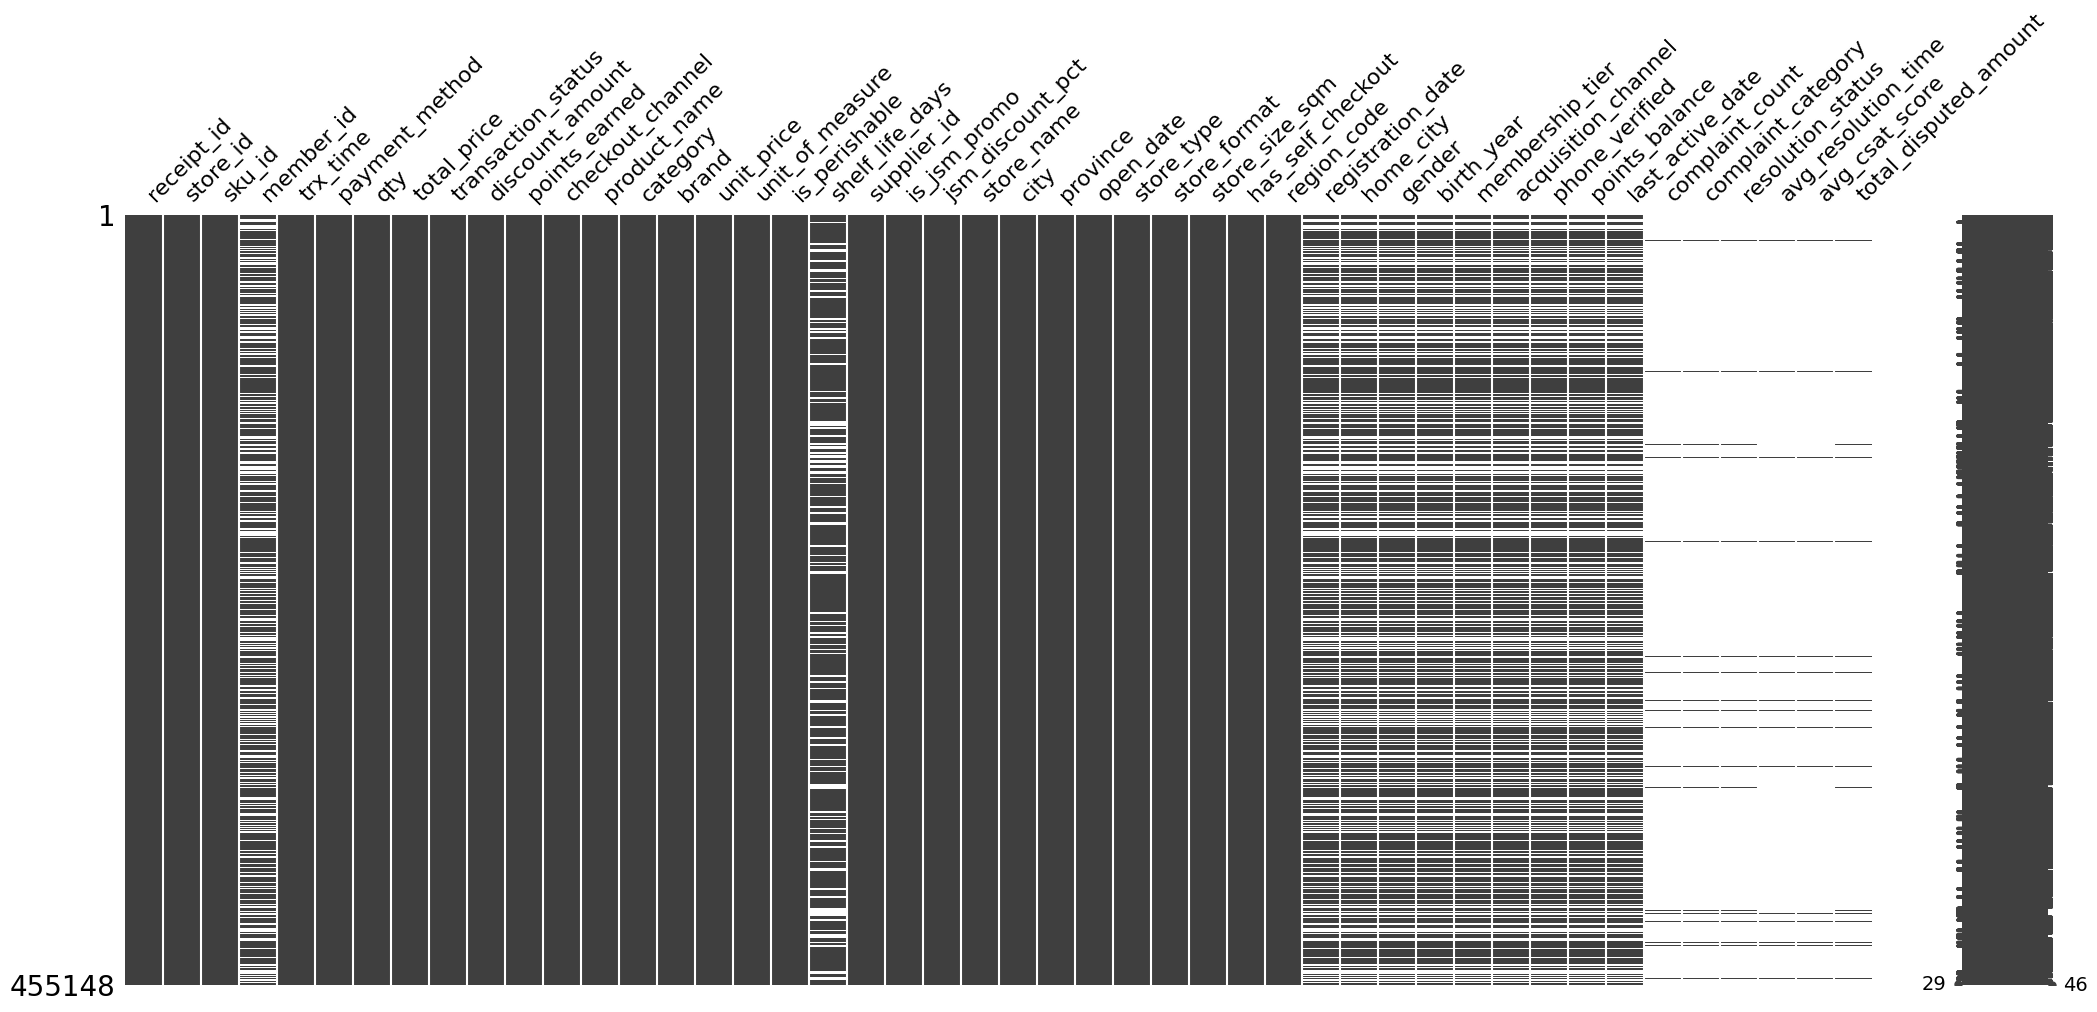

,0
receipt_id,0.00
store_id,0.00
sku_id,0.00
member_id,33.76
trx_time,0.00
payment_method,0.00
qty,0.00
total_price,0.00
transaction_status,0.00
discount_amount,0.00


In [9]:
# Memeriksa nilai null
msno.matrix(df_merged)
plt.show()
df_merged.isna().sum()/df_merged.shape[0]*100

Hasil dari pemeriksaan terhadap missing value pada seluruh dataset menunjukkan bahwa kolom member_id dan seluruh tabel member miliki proporsi missing value sebesar 33,76%. Hal ini berkaitan dengan transaksi yang tidak memiliki identitas pelanggan. Kemudian kolom shelf_life_days memiliki missing value sebesar 19,73%.

Selain itu pada tabel complaint ditemukan bahwa kolom, complaint_count, complaint_category, dan resolution_status memiliki missing values sebesar 97,64%, sedangkan avg_resolution_time dan avg_csat_score sebesar 97,96%.

### **Data Types**

Tahap ini mencakup pemeriksaan tipe data pada setiap kolom dan penyesuaian tipe data berdasarkan karakteristik informasi agar dapat digunakan secara tepat dalam proses analisis.

In [10]:
# Mengubah tipe data kolom tanggal menjadi datetime
date_columns = [
    'open_date',
    'registration_date',
    'last_active_date'
]

for column in date_columns:
    df_merged[column] = pd.to_datetime(
        df_merged[column],
        errors='coerce'
    )

# Mengisi missing value dengan 0 dan mengubah tipe data menjadi integer
df_merged['complaint_count'] = (
    df_merged['complaint_count']
    .fillna(0)
    .astype('Int64')
)

# Melihat informasi struktur dataset
display(df_merged.info(),df_merged.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 455148 entries, 0 to 455147
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype              
---  ------                 --------------   -----              
 0   receipt_id             455148 non-null  object             
 1   store_id               455148 non-null  object             
 2   sku_id                 455148 non-null  object             
 3   member_id              301502 non-null  object             
 4   trx_time               455148 non-null  datetime64[us, UTC]
 5   payment_method         455148 non-null  object             
 6   qty                    455148 non-null  Int64              
 7   total_price            455148 non-null  float64            
 8   transaction_status     455148 non-null  object             
 9   discount_amount        455148 non-null  float64            
 10  points_earned          455148 non-null  Int64              
 11  checkout_channel       455148 non-null 

None

,receipt_id,store_id,sku_id,member_id,trx_time,payment_method,qty,total_price,transaction_status,discount_amount,points_earned,checkout_channel,product_name,category,brand,unit_price,unit_of_measure,is_perishable,shelf_life_days,supplier_id,is_jsm_promo,jsm_discount_pct,store_name,city,province,open_date,store_type,store_format,store_size_sqm,has_self_checkout,region_code,registration_date,home_city,gender,birth_year,membership_tier,acquisition_channel,phone_verified,points_balance,last_active_date,complaint_count,complaint_category,resolution_status,avg_resolution_time,avg_csat_score,total_disputed_amount
0,RCP00129083,SAT-0039,SKU000001,MEM-18001,2023-05-02 13:00:00+00:00,Cash,-5,"-60,500.00",COMPLETED,0.00,0,Kasir Reguler,Air Mineral Aqua,Beverage,Danone-Aqua,"12,100.00",botol,0,641,SUP-107,1,0.31,Alfamart Melati 38,Medan,Sumatera Utara,2021-11-11,Residential/Perumahan,Sedang (Reguler),181,0,REG-SUMUT-4,2021-10-20,Surabaya,P,1981,Reguler,Daftar di Toko,1,28945,2022-12-31,0,NaN,NaN,NaN,NaN,NaN
1,RCP00058071,SAT-0180,SKU000001,MEM-09380,2024-09-27 08:00:00+00:00,Debit BCA,-7,"-58,443.00",COMPLETED,"-26,257.00",0,Kasir Reguler,Air Mineral Aqua,Beverage,Danone-Aqua,"12,100.00",botol,0,641,SUP-107,1,0.31,Alfamart Sudirman 179,Bekasi,Jawa Barat,2023-06-11,Residential/Perumahan,Sedang (Reguler),130,0,REG-JABAR-3,2021-04-27,Depok,P,1968,Reguler,Website,1,10498,2022-07-15,0,NaN,NaN,NaN,NaN,NaN
2,RCP00121686,SAT-0169,SKU000001,MEM-13358,2023-11-02 21:00:00+00:00,Gopay,-2,"-24,200.00",COMPLETED,0.00,0,Kasir Reguler,Air Mineral Aqua,Beverage,Danone-Aqua,"12,100.00",botol,0,641,SUP-107,1,0.31,Alfamart Gatot Subroto 168,Bogor,Jawa Barat,2023-09-15,Residential/Perumahan,Sedang (Reguler),181,0,REG-JABAR-1,2023-02-15,Bandung,P,1972,Reguler,Aplikasi Alfagift,1,48430,2023-05-22,0,NaN,NaN,NaN,NaN,NaN
3,RCP00001532,SAT-0843,SKU000001,None,2023-04-01 20:00:00+00:00,Cash,1,"8,349.00",COMPLETED,"3,751.00",0,Kasir Reguler,Air Mineral Aqua,Beverage,Danone-Aqua,"12,100.00",botol,0,641,SUP-107,1,0.31,Alfamart Gatot Subroto 842,Tangerang,Banten,2022-09-01,Residential/Perumahan,Sedang (Reguler),133,1,REG-BANTEN-4,NaT,NaN,NaN,<NA>,NaN,NaN,<NA>,<NA>,NaT,0,NaN,NaN,NaN,NaN,NaN
4,RCP00001555,SAT-0851,SKU000001,MEM-39956,2023-09-09 10:00:00+00:00,Cash,1,"8,349.00",COMPLETED,"3,751.00",1,Kasir Reguler,Air Mineral Aqua,Beverage,Danone-Aqua,"12,100.00",botol,0,641,SUP-107,1,0.31,Alfamart Melati 850,Medan,Sumatera Utara,2022-10-07,Residential/Perumahan,Sedang (Reguler),166,0,REG-SUMUT-1,2022-06-06,Depok,P,2003,Reguler,Aplikasi Alfagift,1,3867,2023-12-17,0,NaN,NaN,NaN,NaN,NaN


### **Data Duplicate**

Tahap ini mencakup pemeriksaan data yang memiliki nilai duplikat berdasarkan identitas maupun kombinasi kolom tertentu untuk memastikan tidak terdapat pencatatan data berulang yang dapat memengaruhi hasil analisis.

In [11]:
df_merged.duplicated().sum()

np.int64(0)

### **Data Range Constraints**
Tahap ini mencakup pemeriksaan nilai pada setiap kolom berdasarkan rentang dan aturan bisnis yang berlaku untuk mengidentifikasi data yang tidak sesuai dengan karakteristik seharusnya.

In [12]:
# Memeriksa quantity nol atau negatif
print("Quantity <= 0:")
display(
    df_merged[df_merged['qty'] <= 0][
        ['receipt_id', 'sku_id', 'qty', 'total_price', 'transaction_status']
    ].head(10)
)

# Memeriksa nilai transaksi negatif
print("Total Price < 0:")
display(
    df_merged[df_merged['total_price'] < 0][
        ['receipt_id', 'qty', 'total_price', 'transaction_status']
    ].head(10)
)

# Memeriksa diskon negatif
print("Discount Amount < 0:")
display(
    df_merged[df_merged['discount_amount'] < 0][
        ['receipt_id', 'discount_amount', 'transaction_status']
    ].head(10)
)

# Memeriksa harga produk nol atau negatif
print("Unit Price <= 0:")
display(
    df_merged[df_merged['unit_price'] <= 0][
        ['sku_id', 'product_name', 'unit_price']
    ].head(10)
)

# Mengelompokkan quantity berdasarkan status transaksi
df_merged[df_merged['qty'] <= 0].groupby(
    'transaction_status'
).agg(
    total_records=('receipt_id', 'count'),
    total_qty=('qty', 'sum'),
    total_price=('total_price', 'sum')
).reset_index()

Quantity <= 0:


,receipt_id,sku_id,qty,total_price,transaction_status
0,RCP00129083,SKU000001,-5,"-60,500.00",COMPLETED
1,RCP00058071,SKU000001,-7,"-58,443.00",COMPLETED
2,RCP00121686,SKU000001,-2,"-24,200.00",COMPLETED
1096,RCP00140100,SKU000002,-6,"-234,000.00",COMPLETED
1097,RCP00016180,SKU000002,-5,"-195,000.00",COMPLETED
1098,RCP00263159,SKU000002,-4,"-156,000.00",COMPLETED
2237,RCP00152208,SKU000003,-6,"-77,400.00",COMPLETED
2238,RCP00165483,SKU000003,-3,"-38,700.00",COMPLETED
3032,RCP00087546,SKU000004,-7,"-194,600.00",COMPLETED
3033,RCP00155526,SKU000004,-6,"-166,800.00",COMPLETED


Total Price < 0:


,receipt_id,qty,total_price,transaction_status
0,RCP00129083,-5,"-60,500.00",COMPLETED
1,RCP00058071,-7,"-58,443.00",COMPLETED
2,RCP00121686,-2,"-24,200.00",COMPLETED
1096,RCP00140100,-6,"-234,000.00",COMPLETED
1097,RCP00016180,-5,"-195,000.00",COMPLETED
1098,RCP00263159,-4,"-156,000.00",COMPLETED
2237,RCP00152208,-6,"-77,400.00",COMPLETED
2238,RCP00165483,-3,"-38,700.00",COMPLETED
3032,RCP00087546,-7,"-194,600.00",COMPLETED
3033,RCP00155526,-6,"-166,800.00",COMPLETED


Discount Amount < 0:


,receipt_id,discount_amount,transaction_status
1,RCP00058071,"-26,257.00",COMPLETED
7233,RCP00146003,"-62,930.00",COMPLETED
19158,RCP00022023,"-16,280.00",COMPLETED
22062,RCP00182660,"-36,918.00",COMPLETED
22064,RCP00050047,"-21,096.00",COMPLETED
22065,RCP00296694,"-21,096.00",COMPLETED
35941,RCP00292906,"-1,978.00",COMPLETED
43233,RCP00067733,"-13,761.00",COMPLETED
51340,RCP00085030,"-15,252.00",COMPLETED
57551,RCP00230112,"-50,160.00",COMPLETED


Unit Price <= 0:


,sku_id,product_name,unit_price


,transaction_status,total_records,total_qty,total_price
0,COMPLETED,1449,-5959,"-141,405,384.00"
1,VOID,34,-158,"-3,418,898.00"


Hasil pemeriksaan menunjukkan terdapat 1.483 data dengan quantity negatif, terdiri atas 1.449 transaksi berstatus COMPLETED dan 34 transaksi berstatus VOID. Total quantity tercatat sebesar -6.117 unit dengan total nilai transaksi sebesar -Rp144.824.282. Temuan ini menunjukkan bahwa pencatatan quantity dan total price negatif didominasi oleh transaksi COMPLETED.

In [13]:
# Mengelompokkan quantity negatif berdasarkan SKU
df_merged[df_merged['qty'] < 0].groupby(
    ['sku_id', 'product_name']
).agg(
    total_records=('receipt_id', 'count'),
    total_qty=('qty', 'sum'),
    total_price=('total_price', 'sum')
).reset_index().sort_values(
    by='total_records',
    ascending=False
).head(10)

,sku_id,product_name,total_records,total_qty,total_price
311,SKU000329,Indomie Goreng,10,-52,"-795,600.00"
327,SKU000345,Indomie Goreng,8,-33,"-531,300.00"
171,SKU000185,Indomie Goreng,8,-35,"-360,500.00"
456,SKU000484,Indomie Goreng,8,-35,"-404,580.00"
470,SKU000498,Air Mineral Aqua,7,-26,"-998,400.00"
419,SKU000445,Aqua 600ml,7,-29,"-814,956.00"
343,SKU000363,Rokok Sampoerna Mild,7,-18,"-57,600.00"
306,SKU000324,Rokok Sampoerna Mild,7,-18,"-280,800.00"
229,SKU000243,Indomie Goreng,7,-34,"-1,183,200.00"
71,SKU000079,Indomie Goreng,7,-39,"-397,800.00"


Hasil menunjukkan bahwa pencatatan quantity negatif ditemukan pada berbagai produk, dengan Indomie Goreng menjadi produk yang paling sering muncul dalam 10 SKU teratas. Selain itu, produk seperti Air Mineral Aqua, Aqua 600ml, dan Rokok Sampoerna Mild juga menunjukkan pencatatan quantity negatif. Temuan ini mengindikasikan bahwa transaksi negatif tersebar pada beberapa jenis produk dengan frekuensi dan nilai yang berbeda.

In [14]:
# Mengelompokkan quantity negatif berdasarkan tanggal
df_merged[df_merged['qty'] < 0].groupby(
    df_merged['trx_time'].dt.date
).agg(
    total_records=('receipt_id', 'count'),
    total_qty=('qty', 'sum'),
    total_price=('total_price', 'sum')
).reset_index().sort_values(
    by='total_records',
    ascending=False
).head(10)

,trx_time,total_records,total_qty,total_price
559,2023-09-09,6,-30,"-898,310.00"
519,2023-07-21,6,-27,"-607,896.00"
600,2023-11-08,5,-13,"-206,800.00"
247,2022-07-30,5,-21,"-373,560.00"
162,2022-03-29,5,-23,"-638,800.00"
164,2022-03-31,5,-23,"-502,800.00"
222,2022-06-27,5,-22,"-571,300.00"
410,2023-03-03,5,-18,"-534,300.00"
397,2023-02-08,5,-24,"-280,000.00"
467,2023-05-16,5,-12,"-272,400.00"


Hasil menunjukkan bahwa pencatatan quantity negatif tersebar pada berbagai tanggal selama periode 2022–2023. Frekuensi tertinggi ditemukan pada 9 September 2023 dan 21 Juli 2023, masing-masing sebanyak 6 records. Selain itu, nilai transaksi negatif menunjukkan variasi pada setiap tanggal dan tidak selalu sebanding dengan jumlah records.

In [15]:
# Mengambil transaksi dengan total_price negatif
df_negative_price = df_merged[
    df_merged['total_price'] < 0
].copy()

# Mengelompokkan berdasarkan kondisi quantity
df_negative_price['qty_condition'] = (
    df_negative_price['qty'] < 0
).map({
    True: 'Quantity Negatif',
    False: 'Quantity Nol atau Positif'
})

# Menghitung jumlah records berdasarkan kondisi quantity
display(
    df_negative_price.groupby('qty_condition').agg(
        total_records=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_price=('total_price', 'sum')
    ).reset_index()
)

# Menampilkan transaksi dengan total_price negatif,
# tetapi quantity tidak negatif
display(
    df_merged[
        (df_merged['total_price'] < 0) &
        (df_merged['qty'] >= 0)
    ][
        ['receipt_id', 'sku_id', 'qty',
         'total_price', 'transaction_status']
    ].head(10)
)

,qty_condition,total_records,total_qty,total_price
0,Quantity Negatif,1483,-6117,"-144,824,282.00"


,receipt_id,sku_id,qty,total_price,transaction_status


Hasil menunjukkan bahwa terdapat 1.483 records dengan total_price negatif dan seluruhnya memiliki quantity negatif. Total nilai transaksi tercatat sebesar -Rp144.824.282 dengan total quantity -6.117 unit. Tidak ditemukan transaksi dengan total price negatif yang memiliki quantity nol atau positif.*italicized text*

In [16]:
# Mengambil transaksi dengan discount_amount negatif
df_negative_discount = df_merged[
    df_merged['discount_amount'] < 0
].copy()

# Mengelompokkan berdasarkan status transaksi
display(
    df_negative_discount.groupby('transaction_status').agg(
        total_records=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_discount=('discount_amount', 'sum'),
        total_price=('total_price', 'sum')
    ).reset_index()
)

# Mengelompokkan berdasarkan kondisi quantity
df_negative_discount['qty_condition'] = (
    df_negative_discount['qty'] < 0
).map({
    True: 'Quantity Negatif',
    False: 'Quantity Nol atau Positif'
})

display(
    df_negative_discount.groupby('qty_condition').agg(
        total_records=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_discount=('discount_amount', 'sum'),
        total_price=('total_price', 'sum')
    ).reset_index()
)

# Menampilkan 10 contoh transaksi dengan diskon negatif
display(
    df_negative_discount[
        [
            'receipt_id',
            'sku_id',
            'qty',
            'total_price',
            'discount_amount',
            'transaction_status'
        ]
    ].head(10)
)

,transaction_status,total_records,total_qty,total_discount,total_price
0,COMPLETED,102,-438,"-2,864,316.00","-7,360,484.00"
1,VOID,2,-6,"-29,502.00","-63,698.00"


,qty_condition,total_records,total_qty,total_discount,total_price
0,Quantity Negatif,104,-444,"-2,893,818.00","-7,424,182.00"


,receipt_id,sku_id,qty,total_price,discount_amount,transaction_status
1,RCP00058071,SKU000001,-7,"-58,443.00","-26,257.00",COMPLETED
7233,RCP00146003,SKU000009,-5,"-140,070.00","-62,930.00",COMPLETED
19158,RCP00022023,SKU000022,-2,"-65,120.00","-16,280.00",COMPLETED
22062,RCP00182660,SKU000025,-7,"-168,182.00","-36,918.00",COMPLETED
22064,RCP00050047,SKU000025,-4,"-96,104.00","-21,096.00",COMPLETED
22065,RCP00296694,SKU000025,-4,"-96,104.00","-21,096.00",COMPLETED
35941,RCP00292906,SKU000041,-2,"-6,622.00","-1,978.00",COMPLETED
43233,RCP00067733,SKU000049,-3,"-27,939.00","-13,761.00",COMPLETED
51340,RCP00085030,SKU000058,-3,"-33,948.00","-15,252.00",COMPLETED
57551,RCP00230112,SKU000065,-6,"-200,640.00","-50,160.00",COMPLETED


Hasil pemeriksaan menemukan 104 records dengan discount_amount negatif, terdiri atas 102 transaksi berstatus COMPLETED dan 2 transaksi berstatus VOID. Seluruh records tersebut juga memiliki quantity dan total price negatif, dengan total discount sebesar -Rp2.893.818. Temuan ini menunjukkan pola pencatatan negatif yang konsisten pada ketiga kolom transaksi.

In [17]:
# Memeriksa nilai unik is_perishable
print(df_merged['is_perishable'].value_counts(dropna=False))

# Memeriksa nilai selain 0 dan 1
display(
    df_merged[
        ~df_merged['is_perishable'].isin([0, 1]) &
        df_merged['is_perishable'].notna()
    ][['sku_id', 'product_name', 'is_perishable']]
    .drop_duplicates()
)

# Memeriksa nilai unik is_jsm_promo
print(df_merged['is_jsm_promo'].value_counts(dropna=False))

# Memeriksa nilai selain 0 dan 1
display(
    df_merged[
        ~df_merged['is_jsm_promo'].isin([0, 1]) &
        df_merged['is_jsm_promo'].notna()
    ][['sku_id', 'product_name', 'is_jsm_promo']]
    .drop_duplicates()
)

# Memeriksa masa simpan nol atau negatif
display(
    df_merged[
        df_merged['shelf_life_days'] <= 0
    ][
        ['sku_id', 'product_name', 'category', 'shelf_life_days']
    ].drop_duplicates()
)

# Memeriksa nilai unik jsm_discount_pct
print(df_merged['jsm_discount_pct'].describe())

# Memeriksa persentase diskon negatif
display(
    df_merged[
        df_merged['jsm_discount_pct'] < 0
    ][
        ['sku_id', 'product_name', 'is_jsm_promo', 'jsm_discount_pct']
    ].drop_duplicates()
)

# Memeriksa persentase diskon di atas 100
display(
    df_merged[
        df_merged['jsm_discount_pct'] > 100
    ][
        ['sku_id', 'product_name', 'is_jsm_promo', 'jsm_discount_pct']
    ].drop_duplicates()
)

is_perishable
0    434033
1     21115
Name: count, dtype: Int64


,sku_id,product_name,is_perishable


is_jsm_promo
0    351347
1    103801
Name: count, dtype: Int64


,sku_id,product_name,is_jsm_promo


,sku_id,product_name,category,shelf_life_days


count   455,148.00
mean          0.06
std           0.12
min           0.00
25%           0.00
50%           0.00
75%           0.00
max           0.40
Name: jsm_discount_pct, dtype: float64


,sku_id,product_name,is_jsm_promo,jsm_discount_pct


,sku_id,product_name,is_jsm_promo,jsm_discount_pct


Hasil menunjukkan bahwa kolom is_perishable dan is_jsm_promo hanya memiliki nilai 0 dan 1 sesuai dengan karakteristik data biner. Pada kolom shelf_life_days, tidak ditemukan nilai nol atau negatif. Sementara itu, kolom jsm_discount_pct memiliki rentang nilai 0 hingga 0,40 tanpa ditemukan nilai negatif maupun nilai di atas 100.

In [18]:
# Memeriksa statistik luas gerai
print(df_merged['store_size_sqm'].describe())

# Memeriksa luas gerai nol atau negatif
display(
    df_merged[
        df_merged['store_size_sqm'] <= 0
    ][
        ['store_id', 'store_name', 'store_size_sqm']
    ].drop_duplicates()
)

# Memeriksa distribusi nilai has_self_checkout
print(df_merged['has_self_checkout'].value_counts(dropna=False))

# Memeriksa nilai selain 0 dan 1
display(
    df_merged[
        ~df_merged['has_self_checkout'].isin([0, 1]) &
        df_merged['has_self_checkout'].notna()
    ][
        ['store_id', 'store_name', 'has_self_checkout']
    ].drop_duplicates()
)

count   455,148.00
mean        169.73
std          70.58
min          60.00
25%         122.00
50%         164.00
75%         201.00
max         399.00
Name: store_size_sqm, dtype: Float64


,store_id,store_name,store_size_sqm


has_self_checkout
0    373288
1     81860
Name: count, dtype: Int64


,store_id,store_name,has_self_checkout


olom store_size_sqm memiliki rentang luas gerai antara 60 hingga 399 m², tanpa ditemukan nilai nol atau negatif. Sementara itu, kolom has_self_checkout hanya memiliki nilai 0 dan 1, dengan mayoritas records berasal dari gerai yang tidak memiliki fasilitas self-checkout.

In [19]:
# Memeriksa statistik tahun lahir member
print(df_members['birth_year'].describe())

# Memeriksa tahun lahir sebelum 1900
display(
    df_members[
        df_members['birth_year'] < 1900
    ][['member_id', 'birth_year']]
)

# Memeriksa tahun lahir setelah 2026
display(
    df_members[
        df_members['birth_year'] > 2026
    ][['member_id', 'birth_year']]
)

# Memeriksa statistik saldo poin
print(df_members['points_balance'].describe())

# Memeriksa saldo poin negatif
display(
    df_members[
        df_members['points_balance'] < 0
    ][['member_id', 'points_balance']]
)

# Memeriksa distribusi status verifikasi nomor telepon
print(df_members['phone_verified'].value_counts(dropna=False))

# Memeriksa nilai selain 0 dan 1
display(
    df_members[
        ~df_members['phone_verified'].isin([0, 1]) &
        df_members['phone_verified'].notna()
    ][['member_id', 'phone_verified']]
)

count   48,214.00
mean     1,985.42
std         12.13
min      1,965.00
25%      1,975.00
50%      1,985.00
75%      1,996.00
max      2,006.00
Name: birth_year, dtype: Float64


,member_id,birth_year


,member_id,birth_year


count   48,214.00
mean    25,045.36
std     14,431.80
min          2.00
25%     12,495.50
50%     25,178.00
75%     37,548.00
max     49,999.00
Name: points_balance, dtype: Float64


,member_id,points_balance


phone_verified
1    39664
0     8550
Name: count, dtype: Int64


,member_id,phone_verified


kolom birth_year memiliki rentang tahun 1965 hingga 2006 tanpa ditemukan tahun yang tidak wajar berdasarkan batas pemeriksaan. Kolom points_balance juga tidak memiliki saldo poin negatif, sedangkan kolom phone_verified hanya berisi nilai 0 dan 1, dengan 82,27% member telah melakukan verifikasi nomor telepon.

In [20]:
# Memeriksa statistik jumlah komplain
print(df_merged['complaint_count'].describe())

# Memeriksa jumlah komplain negatif atau desimal
display(
    df_merged[
        (df_merged['complaint_count'] < 0) |
        (df_merged['complaint_count'] % 1 != 0)
    ][['receipt_id', 'complaint_count']]
)

# Memeriksa statistik waktu penyelesaian komplain
print(df_merged['avg_resolution_time'].describe())

# Memeriksa waktu penyelesaian negatif
display(
    df_merged[
        df_merged['avg_resolution_time'] < 0
    ][['receipt_id', 'avg_resolution_time']]
)

# Memeriksa statistik skor CSAT
print(df_merged['avg_csat_score'].describe())

# Memeriksa nilai CSAT di luar rentang 1-5
display(
    df_merged[
        (df_merged['avg_csat_score'] < 1) |
        (df_merged['avg_csat_score'] > 5)
    ][['receipt_id', 'avg_csat_score']]
)

# Memeriksa statistik nominal sengketa
print(df_merged['total_disputed_amount'].describe())

# Memeriksa nominal sengketa negatif
display(
    df_merged[
        df_merged['total_disputed_amount'] < 0
    ][['receipt_id', 'total_disputed_amount']]
)


count   455,148.00
mean          0.02
std           0.15
min           0.00
25%           0.00
50%           0.00
75%           0.00
max           1.00
Name: complaint_count, dtype: Float64


,receipt_id,complaint_count


count   9,273.00
mean       27.04
std        24.42
min         0.20
25%        10.80
50%        19.70
75%        34.50
max       255.30
Name: avg_resolution_time, dtype: float64


,receipt_id,avg_resolution_time


count   9,273.00
mean        3.88
std         1.26
min         1.00
25%         3.00
50%         4.00
75%         5.00
max         5.00
Name: avg_csat_score, dtype: float64


,receipt_id,avg_csat_score


count        10,759.00
mean        551,803.00
std       7,054,200.06
min             356.00
25%           9,955.50
50%          22,877.00
75%          56,539.50
max     250,760,631.00
Name: total_disputed_amount, dtype: float64


,receipt_id,total_disputed_amount


kolom complaint_count tidak memiliki nilai negatif atau desimal, avg_resolution_time seluruhnya bernilai positif, dan avg_csat_score berada dalam rentang 1–5. Sementara itu, kolom total_disputed_amount tidak memiliki nilai negatif, meskipun ditemukan nominal maksimum yang cukup tinggi dibandingkan nilai rata-ratanya.

### **Treatment Data Negatif**

Transaksi dengan quantity atau nominal negatif diperiksa terlebih dahulu. Nilai yang lolos pemeriksaan kewajaran diperlakukan sesuai hasil validasi; transaksi yang tidak valid tidak digunakan dalam analisis utama.

In [21]:
# Mengambil transaksi dengan qty atau total_price negatif
df_negative = df_merged[
    (df_merged['qty'] < 0) |
    (df_merged['total_price'] < 0)
].copy()

# Mengabsolutkan nilai quantity dan nominal transaksi
df_negative['qty_abs'] = df_negative['qty'].abs()
df_negative['total_price_abs'] = df_negative['total_price'].abs()

# Menghitung harga per unit berdasarkan nilai absolut
df_negative['unit_price_check'] = (
    df_negative['total_price_abs'] /
    df_negative['qty_abs'].replace(0, np.nan)
)

display(
    df_negative[
        [
            'receipt_id',
            'sku_id',
            'product_name',
            'qty',
            'total_price',
            'unit_price',
            'qty_abs',
            'total_price_abs',
            'unit_price_check'
        ]
    ].head(10)
)

# Memeriksa kewajaran harga berdasarkan master produk
df_negative['price_valid'] = (
    df_negative['unit_price'].notna() &
    df_negative['unit_price_check'].gt(0) &
    (
        df_negative['unit_price_check'] <=
        df_negative['unit_price'] * 1.05
    )
)

# Melihat hasil validasi
display(
    df_negative[
        [
            'receipt_id',
            'sku_id',
            'product_name',
            'qty_abs',
            'total_price_abs',
            'unit_price_check',
            'unit_price',
            'price_valid'
        ]
    ].head(10)
)

# Menghitung hasil validasi transaksi negatif
df_negative_summary = (
    df_negative['price_valid']
    .value_counts()
    .rename(index={
        True: 'Valid',
        False: 'Tidak Valid'
    })
    .reset_index()
)

df_negative_summary.columns = [
    'validation_status',
    'total_records'
]

# Menghitung persentase
df_negative_summary['percentage'] = (
    df_negative_summary['total_records'] /
    len(df_negative) * 100
).round(2)

display(df_negative_summary)

,receipt_id,sku_id,product_name,qty,total_price,unit_price,qty_abs,total_price_abs,unit_price_check
0,RCP00129083,SKU000001,Air Mineral Aqua,-5,"-60,500.00","12,100.00",5,"60,500.00","12,100.00"
1,RCP00058071,SKU000001,Air Mineral Aqua,-7,"-58,443.00","12,100.00",7,"58,443.00","8,349.00"
2,RCP00121686,SKU000001,Air Mineral Aqua,-2,"-24,200.00","12,100.00",2,"24,200.00","12,100.00"
1096,RCP00140100,SKU000002,Indomie Goreng,-6,"-234,000.00","39,000.00",6,"234,000.00","39,000.00"
1097,RCP00016180,SKU000002,Indomie Goreng,-5,"-195,000.00","39,000.00",5,"195,000.00","39,000.00"
1098,RCP00263159,SKU000002,Indomie Goreng,-4,"-156,000.00","39,000.00",4,"156,000.00","39,000.00"
2237,RCP00152208,SKU000003,Bimoli Pouch 2000ml,-6,"-77,400.00","12,900.00",6,"77,400.00","12,900.00"
2238,RCP00165483,SKU000003,Bimoli Pouch 2000ml,-3,"-38,700.00","12,900.00",3,"38,700.00","12,900.00"
3032,RCP00087546,SKU000004,Air Mineral Aqua,-7,"-194,600.00","27,800.00",7,"194,600.00","27,800.00"
3033,RCP00155526,SKU000004,Air Mineral Aqua,-6,"-166,800.00","27,800.00",6,"166,800.00","27,800.00"


,receipt_id,sku_id,product_name,qty_abs,total_price_abs,unit_price_check,unit_price,price_valid
0,RCP00129083,SKU000001,Air Mineral Aqua,5,"60,500.00","12,100.00","12,100.00",True
1,RCP00058071,SKU000001,Air Mineral Aqua,7,"58,443.00","8,349.00","12,100.00",True
2,RCP00121686,SKU000001,Air Mineral Aqua,2,"24,200.00","12,100.00","12,100.00",True
1096,RCP00140100,SKU000002,Indomie Goreng,6,"234,000.00","39,000.00","39,000.00",True
1097,RCP00016180,SKU000002,Indomie Goreng,5,"195,000.00","39,000.00","39,000.00",True
1098,RCP00263159,SKU000002,Indomie Goreng,4,"156,000.00","39,000.00","39,000.00",True
2237,RCP00152208,SKU000003,Bimoli Pouch 2000ml,6,"77,400.00","12,900.00","12,900.00",True
2238,RCP00165483,SKU000003,Bimoli Pouch 2000ml,3,"38,700.00","12,900.00","12,900.00",True
3032,RCP00087546,SKU000004,Air Mineral Aqua,7,"194,600.00","27,800.00","27,800.00",True
3033,RCP00155526,SKU000004,Air Mineral Aqua,6,"166,800.00","27,800.00","27,800.00",True


,validation_status,total_records,percentage
0,Valid,1483,100.00


In [22]:
# Membuat salinan dataset
df_cleaned = df_merged.copy()

# Mengambil indeks transaksi negatif yang valid
valid_idx = df_negative.index[
    df_negative['price_valid']
]

# Mengabsolutkan quantity dan total price
df_cleaned.loc[valid_idx, 'qty'] = (
    df_cleaned.loc[valid_idx, 'qty'].abs()
)

df_cleaned.loc[valid_idx, 'total_price'] = (
    df_cleaned.loc[valid_idx, 'total_price'].abs()
)

# Memeriksa jumlah transaksi negatif setelah treatment
print("Sisa qty negatif:",
      (df_cleaned.loc[valid_idx, 'qty'] < 0).sum())

print("Sisa total_price negatif:",
      (df_cleaned.loc[valid_idx, 'total_price'] < 0).sum())

# Memeriksa seluruh nilai negatif
print("Total qty negatif:",
      (df_cleaned['qty'] < 0).sum())

print("Total total_price negatif:",
      (df_cleaned['total_price'] < 0).sum())

print("Total discount negatif:",
      (df_cleaned['discount_amount'] < 0).sum())

Sisa qty negatif: 0
Sisa total_price negatif: 0
Total qty negatif: 0
Total total_price negatif: 0
Total discount negatif: 104


In [23]:
# Mengambil transaksi dengan discount_amount negatif
df_negative_discount = df_cleaned[
    df_cleaned['discount_amount'] < 0
].copy()

# Melihat jumlah berdasarkan transaction_status
display(
    df_negative_discount.groupby('transaction_status')
    .agg(
        total_records=('receipt_id', 'count'),
        total_discount=('discount_amount', 'sum')
    )
    .reset_index()
)

# Melihat contoh transaksi
display(
    df_negative_discount[
        [
            'receipt_id',
            'sku_id',
            'product_name',
            'qty',
            'total_price',
            'discount_amount',
            'transaction_status',
            'is_jsm_promo'
        ]
    ].head(10)
)

,transaction_status,total_records,total_discount
0,COMPLETED,102,"-2,864,316.00"
1,VOID,2,"-29,502.00"


,receipt_id,sku_id,product_name,qty,total_price,discount_amount,transaction_status,is_jsm_promo
1,RCP00058071,SKU000001,Air Mineral Aqua,7,"58,443.00","-26,257.00",COMPLETED,1
7233,RCP00146003,SKU000009,Bimoli Pouch 2000ml,5,"140,070.00","-62,930.00",COMPLETED,1
19158,RCP00022023,SKU000022,Minyak Bimoli 2L,2,"65,120.00","-16,280.00",COMPLETED,1
22062,RCP00182660,SKU000025,Minyak Bimoli 2L,7,"168,182.00","-36,918.00",COMPLETED,1
22064,RCP00050047,SKU000025,Minyak Bimoli 2L,4,"96,104.00","-21,096.00",COMPLETED,1
22065,RCP00296694,SKU000025,Minyak Bimoli 2L,4,"96,104.00","-21,096.00",COMPLETED,1
35941,RCP00292906,SKU000041,Air Mineral Aqua,2,"6,622.00","-1,978.00",COMPLETED,1
43233,RCP00067733,SKU000049,Indomie Goreng,3,"27,939.00","-13,761.00",COMPLETED,1
51340,RCP00085030,SKU000058,Aqua 600ml,3,"33,948.00","-15,252.00",COMPLETED,1
57551,RCP00230112,SKU000065,Pepsodent 190g,6,"200,640.00","-50,160.00",COMPLETED,1


In [24]:
# Memeriksa irisan indeks transaksi negatif
print(
    "Jumlah discount negatif yang sebelumnya memiliki qty/price negatif:",
    len(df_negative_discount.index.intersection(valid_idx))
)

# Menghitung nilai dasar produk berdasarkan harga master
df_negative_discount['gross_price'] = (
    df_negative_discount['qty'] *
    df_negative_discount['unit_price']
)

# Mengabsolutkan nilai discount untuk pemeriksaan
df_negative_discount['discount_abs'] = (
    df_negative_discount['discount_amount'].abs()
)

# Memeriksa kewajaran discount
df_negative_discount['discount_valid'] = (
    (df_negative_discount['discount_abs'] <=
     df_negative_discount['gross_price']) &
    (df_negative_discount['discount_abs'] >= 0)
)

# Rekap hasil validasi
display(
    df_negative_discount['discount_valid']
    .value_counts()
    .rename(index={
        True: 'Valid',
        False: 'Tidak Valid'
    })
)

Jumlah discount negatif yang sebelumnya memiliki qty/price negatif: 104


,count
discount_valid,
Valid,104


In [25]:
# Mengambil indeks transaksi dengan discount negatif
negative_discount_idx = df_cleaned.index[
    df_cleaned['discount_amount'] < 0
]

# Mengabsolutkan nilai discount
df_cleaned.loc[
    negative_discount_idx, 'discount_amount'
] = df_cleaned.loc[
    negative_discount_idx, 'discount_amount'
].abs()

# Memeriksa sisa nilai negatif
print("Sisa qty negatif:",
      (df_cleaned['qty'] < 0).sum())

print("Sisa total_price negatif:",
      (df_cleaned['total_price'] < 0).sum())

print("Sisa discount_amount negatif:",
      (df_cleaned['discount_amount'] < 0).sum())



Sisa qty negatif: 0
Sisa total_price negatif: 0
Sisa discount_amount negatif: 0


### **Outliers**
Tahap ini mencakup identifikasi nilai ekstrem yang memiliki perbedaan signifikan dari mayoritas data, serta evaluasi terhadap kemungkinan kesalahan pencatatan atau pola transaksi tidak biasa yang relevan dengan tujuan analisis.

In [26]:
# Mengambil transaksi completed dengan quantity positif
df_qty = df_merged[
    (df_merged['transaction_status'] == 'COMPLETED') &
    (df_merged['qty'] > 0)
].copy()

# Menghitung kuartil dan IQR
Q1 = df_qty['qty'].quantile(0.25)
Q3 = df_qty['qty'].quantile(0.75)
IQR = Q3 - Q1

# Menentukan batas outlier
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Mengambil data yang terindikasi outlier
df_qty_outliers = df_qty[
    df_qty['qty'] > upper_bound
].copy()

print("Total transaksi:", len(df_qty))
print("Total outlier:", len(df_qty_outliers))
print(
    "Persentase outlier:",
    round(len(df_qty_outliers) / len(df_qty) * 100, 2),
    "%"
)

# Menampilkan 10 transaksi dengan quantity terbesar
display(
    df_qty_outliers[
        [
            'receipt_id',
            'trx_time',
            'sku_id',
            'product_name',
            'qty',
            'total_price',
            'transaction_status',
            'is_jsm_promo'
        ]
    ].sort_values(
        by='qty',
        ascending=False
    ).head(10)
)

Q1: 1.0
Q3: 4.0
IQR: 3.0
Lower Bound: -3.5
Upper Bound: 8.5
Total transaksi: 439675
Total outlier: 54403
Persentase outlier: 12.37 %


,receipt_id,trx_time,sku_id,product_name,qty,total_price,transaction_status,is_jsm_promo
240609,RCP00109596,2022-11-08 17:00:00+00:00,SKU000266,Rokok Sampoerna Mild,9975,"95,760,000.00",COMPLETED,0
131977,RCP00213578,2021-08-18 15:00:00+00:00,SKU000146,Indomie Goreng,9828,"440,294,400.00",COMPLETED,0
17450,RCP00208482,2022-04-30 08:00:00+00:00,SKU000019,Rokok Sampoerna Mild,9803,"290,168,800.00",COMPLETED,0
246552,RCP00297626,2023-07-26 13:00:00+00:00,SKU000272,Minyak Goreng Bimoli,9771,"287,267,400.00",COMPLETED,1
223545,RCP00036148,2023-12-31 21:00:00+00:00,SKU000247,Aqua 600ml,9703,"62,099,200.00",COMPLETED,0
386036,RCP00165678,2023-05-31 03:00:00+00:00,SKU000427,Minyak Bimoli 2L,9671,"401,346,500.00",COMPLETED,0
321483,RCP00195483,2024-02-12 11:00:00+00:00,SKU000354,Pepsodent 190g,9645,"370,368,000.00",COMPLETED,0
316764,RCP00178437,2022-09-07 19:00:00+00:00,SKU000349,Air Mineral Aqua,9535,"73,419,500.00",COMPLETED,0
369647,RCP00102406,2024-03-05 07:00:00+00:00,SKU000408,Aqua 600ml,9481,"233,232,600.00",COMPLETED,0
287559,RCP00064352,2024-08-12 08:00:00+00:00,SKU000317,Rokok Sampoerna Mild,9378,"415,445,400.00",COMPLETED,0


Pemeriksaan menggunakan metode IQR menunjukkan bahwa batas atas pembelian berada pada 8,5 unit, sehingga transaksi dengan quantity 9 unit atau lebih terindikasi sebagai outlier. Ditemukan 54.403 records atau 12,37% dari total transaksi yang diperiksa. Beberapa transaksi memiliki quantity mencapai lebih dari 9.000 unit dengan nilai transaksi hingga ratusan juta rupiah. Namun, sebagian besar contoh transaksi dengan quantity tertinggi bukan merupakan produk Promo JSM.

In [27]:
# Menghitung batas outlier untuk setiap SKU
df_sku_iqr = (
    df_qty.groupby(['sku_id', 'product_name'])['qty']
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

# Menghitung IQR dan batas atas
df_sku_iqr['IQR'] = df_sku_iqr['Q3'] - df_sku_iqr['Q1']
df_sku_iqr['upper_bound'] = (
    df_sku_iqr['Q3'] + 1.5 * df_sku_iqr['IQR']
)

display(df_sku_iqr.head(10))

,sku_id,product_name,Q1,Q3,IQR,upper_bound
0,SKU000001,Air Mineral Aqua,1,16.00,15.00,38.50
1,SKU000002,Indomie Goreng,1,24.00,23.00,58.50
2,SKU000003,Bimoli Pouch 2000ml,1,4.00,3.00,8.50
3,SKU000004,Air Mineral Aqua,1,4.00,3.00,8.50
4,SKU000005,Rokok Sampoerna Mild,1,4.00,3.00,8.50
5,SKU000006,Air Mineral Aqua,1,4.00,3.00,8.50
6,SKU000007,Aqua 600ml,1,3.00,2.00,6.00
7,SKU000008,Pepsodent 190g,1,4.00,3.00,8.50
8,SKU000009,Bimoli Pouch 2000ml,1,22.00,21.00,53.50
9,SKU000010,Minyak Bimoli 2L,1,3.00,2.00,6.00


In [28]:
# Menggabungkan batas IQR setiap SKU ke data transaksi
df_qty_sku = df_qty.merge(
    df_sku_iqr[['sku_id', 'upper_bound']],
    on='sku_id',
    how='left'
)

# Mengambil transaksi yang melebihi batas atas masing-masing SKU
df_qty_sku_outliers = df_qty_sku[
    df_qty_sku['qty'] > df_qty_sku['upper_bound']
].copy()

# Menghitung jumlah dan persentase outlier
print("Total transaksi:", len(df_qty_sku))
print("Total outlier:", len(df_qty_sku_outliers))
print(
    "Persentase outlier:",
    round(len(df_qty_sku_outliers) / len(df_qty_sku) * 100, 2),
    "%"
)

display(
    df_qty_sku_outliers[
        [
            'receipt_id',
            'trx_time',
            'sku_id',
            'product_name',
            'qty',
            'upper_bound',
            'total_price',
            'is_jsm_promo'
        ]
    ].sort_values(
        by='qty',
        ascending=False
    ).head(10)
)

Total transaksi: 439675
Total outlier: 36681
Persentase outlier: 8.34 %


,receipt_id,trx_time,sku_id,product_name,qty,upper_bound,total_price,is_jsm_promo
232603,RCP00109596,2022-11-08 17:00:00+00:00,SKU000266,Rokok Sampoerna Mild,9975,7.25,"95,760,000.00",0
127717,RCP00213578,2021-08-18 15:00:00+00:00,SKU000146,Indomie Goreng,9828,8.50,"440,294,400.00",0
16957,RCP00208482,2022-04-30 08:00:00+00:00,SKU000019,Rokok Sampoerna Mild,9803,8.50,"290,168,800.00",0
238352,RCP00297626,2023-07-26 13:00:00+00:00,SKU000272,Minyak Goreng Bimoli,9771,48.50,"287,267,400.00",1
216024,RCP00036148,2023-12-31 21:00:00+00:00,SKU000247,Aqua 600ml,9703,8.50,"62,099,200.00",0
373138,RCP00165678,2023-05-31 03:00:00+00:00,SKU000427,Minyak Bimoli 2L,9671,6.00,"401,346,500.00",0
310795,RCP00195483,2024-02-12 11:00:00+00:00,SKU000354,Pepsodent 190g,9645,8.50,"370,368,000.00",0
306179,RCP00178437,2022-09-07 19:00:00+00:00,SKU000349,Air Mineral Aqua,9535,8.50,"73,419,500.00",0
357297,RCP00102406,2024-03-05 07:00:00+00:00,SKU000408,Aqua 600ml,9481,8.50,"233,232,600.00",0
278001,RCP00064352,2024-08-12 08:00:00+00:00,SKU000317,Rokok Sampoerna Mild,9378,6.00,"415,445,400.00",0


Pemeriksaan menggunakan metode IQR berdasarkan masing-masing SKU menunjukkan 36.681 records atau 8,34% dari total transaksi terindikasi sebagai outlier. Jumlah ini lebih rendah dibandingkan penggunaan batas IQR secara keseluruhan yang menghasilkan 54.403 records. Beberapa transaksi memiliki quantity mencapai lebih dari 9.000 unit, tetapi mayoritas dari 10 transaksi dengan quantity tertinggi bukan merupakan produk Promo JSM.

In [29]:
# Mengambil transaksi outlier khusus produk Promo JSM
df_jsm_outliers = df_qty_sku_outliers[
    df_qty_sku_outliers['is_jsm_promo'] == 1
].copy()

# Ringkasan transaksi outlier Promo JSM
print("Total transaksi outlier JSM:", len(df_jsm_outliers))
print("Jumlah SKU:", df_jsm_outliers['sku_id'].nunique())
print("Total quantity:", df_jsm_outliers['qty'].sum())
print("Total nilai transaksi:", df_jsm_outliers['total_price'].sum())

# Mengelompokkan outlier berdasarkan SKU
df_jsm_outliers_summary = (
    df_jsm_outliers.groupby(
        ['sku_id', 'product_name']
    )
    .agg(
        total_records=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_price=('total_price', 'sum')
    )
    .reset_index()
    .sort_values(
        by='total_records',
        ascending=False
    )
)

display(df_jsm_outliers_summary.head(10))



Total transaksi outlier JSM: 12758
Jumlah SKU: 90
Total quantity: 1057850
Total nilai transaksi: 19695476115.0


,sku_id,product_name,total_records,total_qty,total_price
40,SKU000217,Minyak Goreng Bimoli,219,12719,"298,752,300.00"
53,SKU000291,Indomie Goreng,203,11593,"323,453,512.00"
22,SKU000119,Minyak Bimoli 2L,190,11496,"295,613,136.00"
78,SKU000445,Aqua 600ml,190,12843,"316,478,874.00"
81,SKU000449,Indomie Goreng,187,11102,"337,432,230.00"
61,SKU000340,Indomie Goreng,185,16435,"430,608,750.00"
84,SKU000475,Indomie Goreng,173,11274,"115,550,550.00"
35,SKU000205,Air Mineral Aqua,172,12227,"383,593,424.00"
37,SKU000211,Pepsodent 190g,169,20381,"537,183,120.00"
18,SKU000095,Air Mineral Aqua,168,12214,"44,293,584.00"


Hasil pemeriksaan menggunakan metode IQR berdasarkan masing-masing SKU menunjukkan bahwa terdapat 12.758 records pembelian produk Promo JSM yang terindikasi outlier, mencakup 90 SKU dengan total quantity 1.057.850 unit dan nilai transaksi sekitar Rp1,97 miliar. Produk yang memiliki frekuensi outlier tertinggi antara lain Minyak Goreng Bimoli, Indomie Goreng, dan Minyak Bimoli 2L.

In [30]:
# Mengambil nama hari dari tanggal transaksi
df_jsm_outliers['day_name'] = (
    df_jsm_outliers['trx_time'].dt.day_name()
)

# Mengelompokkan outlier berdasarkan hari
df_jsm_day = (
    df_jsm_outliers.groupby('day_name')
    .agg(
        total_records=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_price=('total_price', 'sum')
    )
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
    .reset_index()
)

display(df_jsm_day)

,day_name,total_records,total_qty,total_price
0,Monday,600,66790,"1,822,258,900.00"
1,Tuesday,588,55260,"1,191,506,900.00"
2,Wednesday,589,70765,"1,813,065,600.00"
3,Thursday,572,71311,"1,507,087,100.00"
4,Friday,3508,265621,"4,579,248,922.00"
5,Saturday,3477,259929,"4,258,652,009.00"
6,Sunday,3424,268174,"4,523,656,684.00"


Hasil pengelompokan transaksi outlier produk Promo JSM berdasarkan hari menunjukkan bahwa 10.409 records atau 81,59% terjadi pada Jumat–Minggu, dengan total quantity 793.724 unit dan nilai transaksi sekitar Rp13,36 miliar. Hari Jumat memiliki jumlah records terbanyak, yaitu 3.508, sedangkan Minggu mencatat total quantity terbesar sebesar 268.174 unit.

# **Data Analysis**
### **Exploratory Data Analysis (EDA)**

Tahap ini mencakup eksplorasi dan analisis data transaksi, produk, pelanggan, gerai, serta komplain untuk mengidentifikasi pola pembelian, tren penjualan, karakteristik transaksi, dan indikasi pembelian tidak biasa yang berkaitan dengan Promo JSM.

### **1. Sales Overview & Trend**

Membandingkan performa penjualan JSM dan Non-JSM serta melihat perubahan penjualan berdasarkan waktu dan hari transaksi.

,is_jsm_promo,total_records,total_quantity,total_sales,avg_quantity,avg_sales,promo_category,sales_contribution_pct
0,0,338430,1869504,"46,696,410,800.00",5.52,"137,979.53",Non-JSM,58.79
1,1,101245,1747571,"32,729,120,658.00",17.26,"323,266.54",JSM,41.21


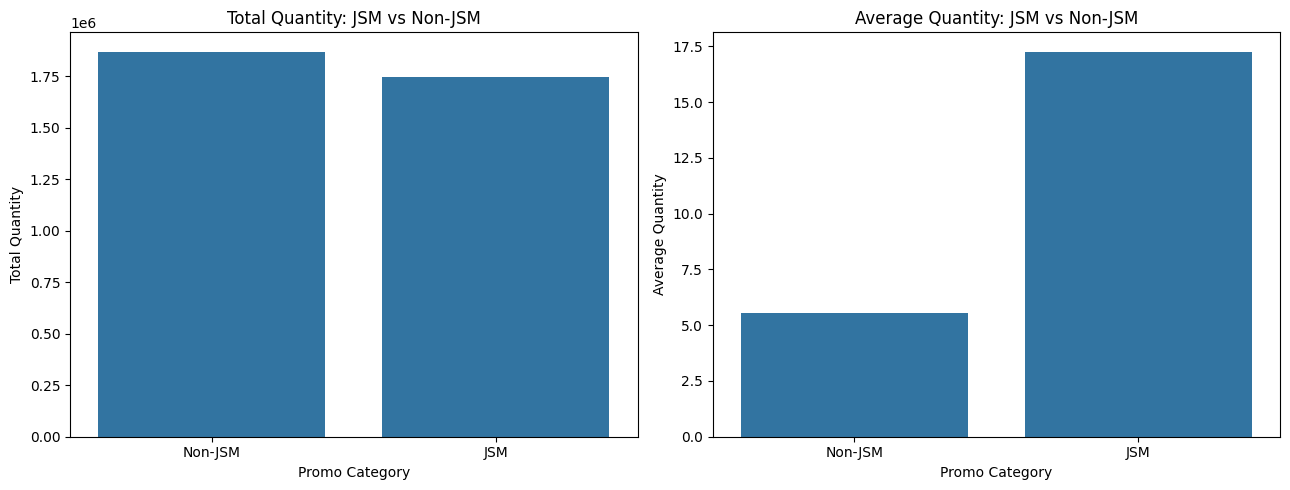

In [31]:

# Memastikan hanya transaksi valid yang dianalisis
df_analysis = df_merged[
    (df_merged['transaction_status'] == 'COMPLETED') &
    (df_merged['qty'] > 0) &
    (df_merged['total_price'] > 0)
].copy()

# Mengelompokkan performa penjualan JSM dan Non-JSM
sales_overview = (
    df_analysis
    .groupby('is_jsm_promo')
    .agg(
        total_records=('receipt_id', 'count'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum'),
        avg_quantity=('qty', 'mean'),
        avg_sales=('total_price', 'mean')
    )
    .reset_index()
)

# Mengubah label kategori
sales_overview['promo_category'] = (
    sales_overview['is_jsm_promo']
    .map({1: 'JSM', 0: 'Non-JSM'})
)

# Menghitung kontribusi penjualan
sales_overview['sales_contribution_pct'] = (
    sales_overview['total_sales'] /
    sales_overview['total_sales'].sum() * 100
)

display(sales_overview)

# Menyiapkan visualisasi
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik total quantity
sns.barplot(
    data=sales_overview,
    x='promo_category',
    y='total_quantity',
    ax=axes[0]
)
axes[0].set_title('Total Quantity: JSM vs Non-JSM')
axes[0].set_xlabel('Promo Category')
axes[0].set_ylabel('Total Quantity')

# Grafik rata-rata quantity
sns.barplot(
    data=sales_overview,
    x='promo_category',
    y='avg_quantity',
    ax=axes[1]
)
axes[1].set_title('Average Quantity: JSM vs Non-JSM')
axes[1].set_xlabel('Promo Category')
axes[1].set_ylabel('Average Quantity')

plt.tight_layout()
plt.show()



Produk JSM memiliki rata-rata kuantitas dan nominal penjualan per record yang lebih tinggi dibandingkan Non-JSM. Temuan ini menarik untuk ditelusuri lebih lanjut guna mengetahui apakah terdapat pola pembelian dalam jumlah besar pada produk promo.

/tmp/ipykernel_457/2979191978.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_analysis['trx_time'].dt.to_period('M').dt.to_timestamp()


,month_year,is_jsm_promo,total_quantity,total_sales,promo_category
0,2020-10-01,0,1161,"33,933,200.00",Non-JSM
1,2020-10-01,1,111,"2,750,571.00",JSM
2,2020-11-01,0,497,"12,410,900.00",Non-JSM
3,2020-11-01,1,51,"922,657.00",JSM
4,2020-12-01,0,599,"15,168,100.00",Non-JSM


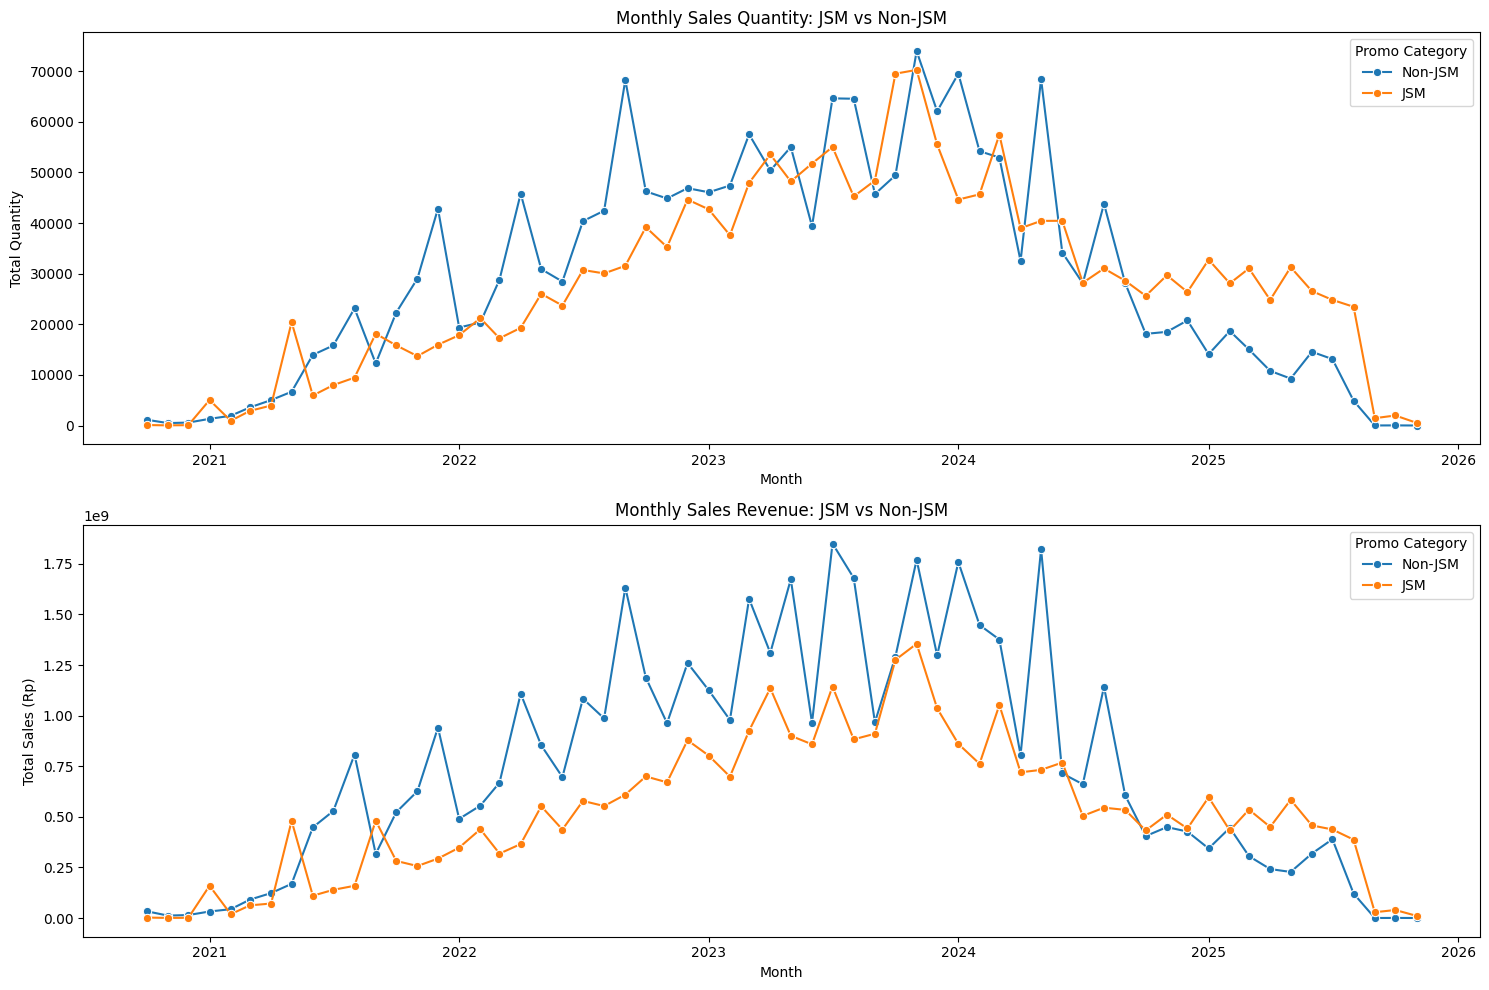

In [32]:
# Memastikan format tanggal
df_analysis['trx_time'] = pd.to_datetime(df_analysis['trx_time'])

# Membuat kolom bulan dan tahun
df_analysis['month_year'] = (
    df_analysis['trx_time'].dt.to_period('M').dt.to_timestamp()
)

# Mengelompokkan penjualan berdasarkan bulan dan kategori promo
monthly_sales = (
    df_analysis
    .groupby(['month_year', 'is_jsm_promo'])
    .agg(
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum')
    )
    .reset_index()
)

# Memberikan label kategori promo
monthly_sales['promo_category'] = (
    monthly_sales['is_jsm_promo']
    .map({1: 'JSM', 0: 'Non-JSM'})
)

display(monthly_sales.head())


fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Tren total quantity
sns.lineplot(
    data=monthly_sales,
    x='month_year',
    y='total_quantity',
    hue='promo_category',
    marker='o',
    ax=axes[0]
)

axes[0].set_title('Monthly Sales Quantity: JSM vs Non-JSM')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Total Quantity')
axes[0].legend(title='Promo Category')

# Tren total sales
sns.lineplot(
    data=monthly_sales,
    x='month_year',
    y='total_sales',
    hue='promo_category',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Monthly Sales Revenue: JSM vs Non-JSM')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total Sales (Rp)')
axes[1].legend(title='Promo Category')

plt.tight_layout()
plt.show()


1. **Pertumbuhan penjualan**: JSM dan Non-JSM sama-sama mengalami peningkatan aktivitas penjualan hingga sekitar 2023. Hal ini menunjukkan adanya pertumbuhan kuantitas dan nominal penjualan pada kedua kategori.
2. **Perbedaan pola penjualan**: Meskipun total nominal penjualan JSM lebih rendah, kuantitas penjualannya pada beberapa bulan mampu menyamai atau melampaui Non-JSM. Ini menarik untuk ditelusuri lebih lanjut dari sisi jumlah pembelian per transaksi.
3. **Penurunan penjualan**: Kedua kategori mengalami penurunan setelah periode puncaknya. Namun, penyebab penurunan belum dapat disimpulkan hanya dari grafik ini.

,day_name,is_jsm_promo,total_records,total_quantity,total_sales,avg_quantity,promo_category
2,Monday,0,46945,278692,"7,077,383,800.00",5.94,Non-JSM
3,Monday,1,11734,123254,"3,138,541,400.00",10.50,JSM
10,Tuesday,0,46475,235634,"5,935,689,700.00",5.07,Non-JSM
11,Tuesday,1,11544,108653,"2,453,092,800.00",9.41,JSM
12,Wednesday,0,46604,292417,"7,029,756,500.00",6.27,Non-JSM
13,Wednesday,1,11681,125819,"3,099,602,800.00",10.77,JSM
8,Thursday,0,46614,261300,"6,891,600,500.00",5.61,Non-JSM
9,Thursday,1,11569,126818,"2,815,371,200.00",10.96,JSM
0,Friday,0,50583,253521,"6,089,081,100.00",5.01,Non-JSM
1,Friday,1,18290,419925,"7,160,116,347.00",22.96,JSM


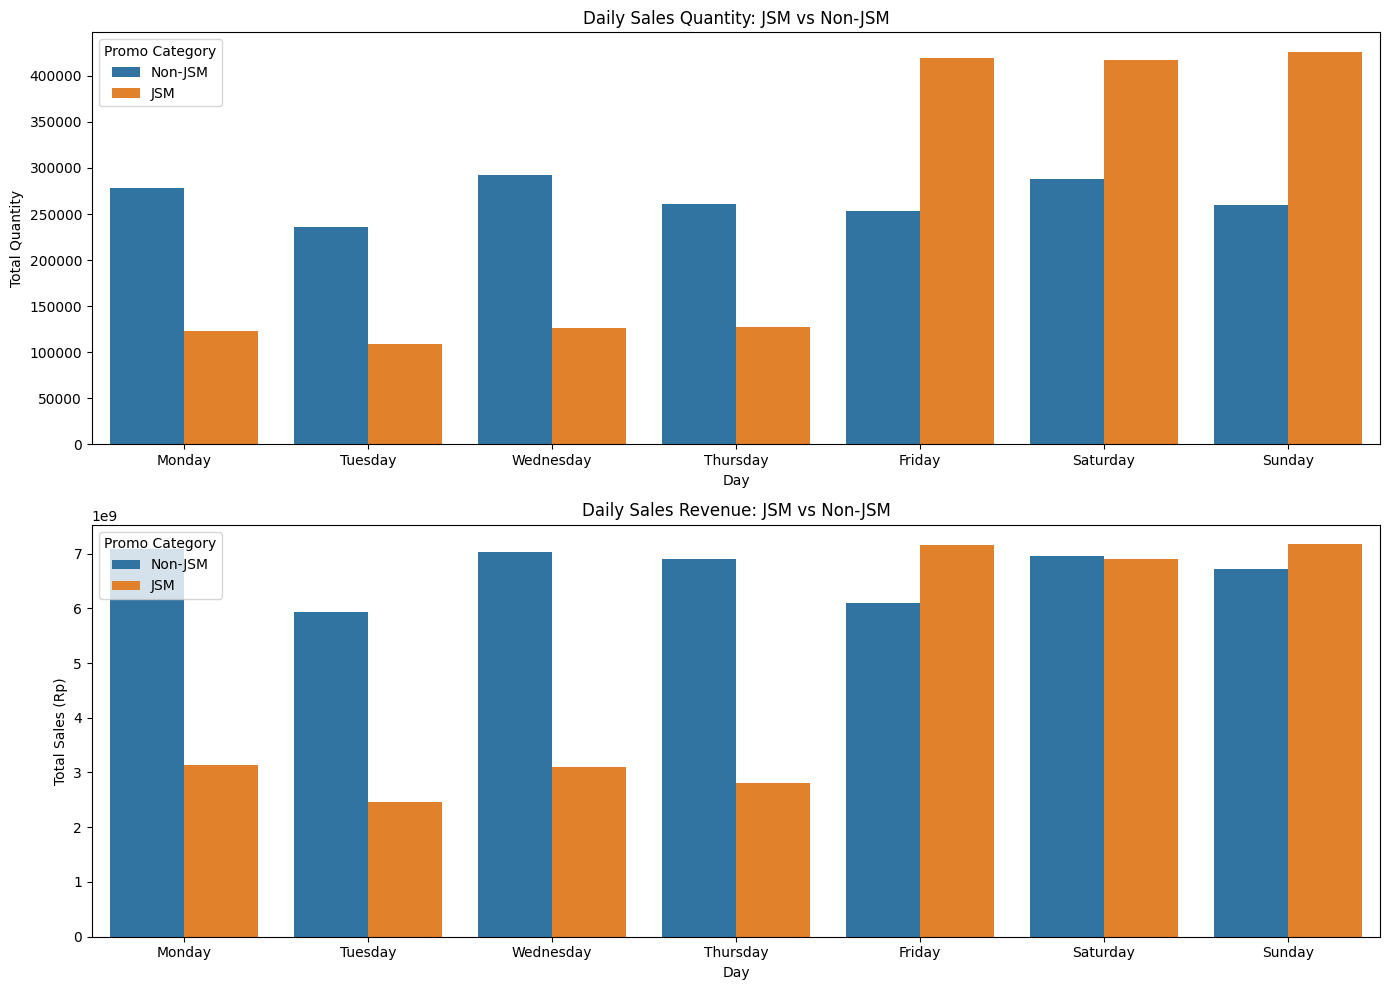

In [33]:

# Membuat kolom nama hari
df_analysis['day_name'] = df_analysis['trx_time'].dt.day_name()

# Menentukan urutan hari
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# Mengelompokkan data berdasarkan hari dan kategori promo
daily_sales = (
    df_analysis
    .groupby(['day_name', 'is_jsm_promo'])
    .agg(
        total_records=('receipt_id', 'count'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum'),
        avg_quantity=('qty', 'mean')
    )
    .reset_index()
)

# Mengurutkan hari
daily_sales['day_name'] = pd.Categorical(
    daily_sales['day_name'],
    categories=day_order,
    ordered=True
)

daily_sales = daily_sales.sort_values('day_name')

# Memberikan label kategori promo
daily_sales['promo_category'] = (
    daily_sales['is_jsm_promo']
    .map({1: 'JSM', 0: 'Non-JSM'})
)

display(daily_sales)


fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Grafik total quantity berdasarkan hari
sns.barplot(
    data=daily_sales,
    x='day_name',
    y='total_quantity',
    hue='promo_category',
    ax=axes[0]
)

axes[0].set_title('Daily Sales Quantity: JSM vs Non-JSM')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Total Quantity')
axes[0].legend(title='Promo Category')

# Grafik total sales berdasarkan hari
sns.barplot(
    data=daily_sales,
    x='day_name',
    y='total_sales',
    hue='promo_category',
    ax=axes[1]
)

axes[1].set_title('Daily Sales Revenue: JSM vs Non-JSM')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Total Sales (Rp)')
axes[1].legend(title='Promo Category')

plt.tight_layout()
plt.show()



Berdasarkan analisis penjualan harian, produk JSM menunjukkan peningkatan aktivitas penjualan yang signifikan pada Jumat, Sabtu, dan Minggu. Total kuantitas penjualan meningkat dari kisaran 108 ribu–127 ribu unit pada hari kerja menjadi sekitar 417 ribu–426 ribu unit pada akhir pekan.

Peningkatan tersebut juga terlihat pada nominal penjualan dan rata-rata kuantitas pembelian per record. Rata-rata quantity produk JSM pada akhir pekan mencapai sekitar 23 unit, lebih dari dua kali lipat dibandingkan hari kerja.

Sebaliknya, penjualan produk Non-JSM cenderung lebih stabil sepanjang minggu. Temuan ini menunjukkan adanya pola peningkatan aktivitas pembelian SKU JSM pada akhir pekan yang perlu ditelusuri lebih lanjut untuk mengidentifikasi potensi pembelian dalam jumlah besar.

,day_type,is_jsm_promo,total_records,total_quantity,total_sales,avg_quantity,avg_sales,promo_category
0,Weekday,0,186638,1068043,"26,934,430,500.00",5.72,"144,313.75",Non-JSM
1,Weekday,1,46528,484544,"11,506,608,200.00",10.41,"247,305.02",JSM
2,Weekend,0,151792,801461,"19,761,980,300.00",5.28,"130,191.18",Non-JSM
3,Weekend,1,54717,1263027,"21,222,512,458.00",23.08,"387,859.58",JSM


,weekday,weekend,increase_pct
total_records,46528,54717,17.60
total_quantity,484544,1263027,160.66
total_sales,"11,506,608,200.00","21,222,512,458.00",84.44
avg_quantity,10.41,23.08,121.65
avg_sales,"247,305.02","387,859.58",56.83


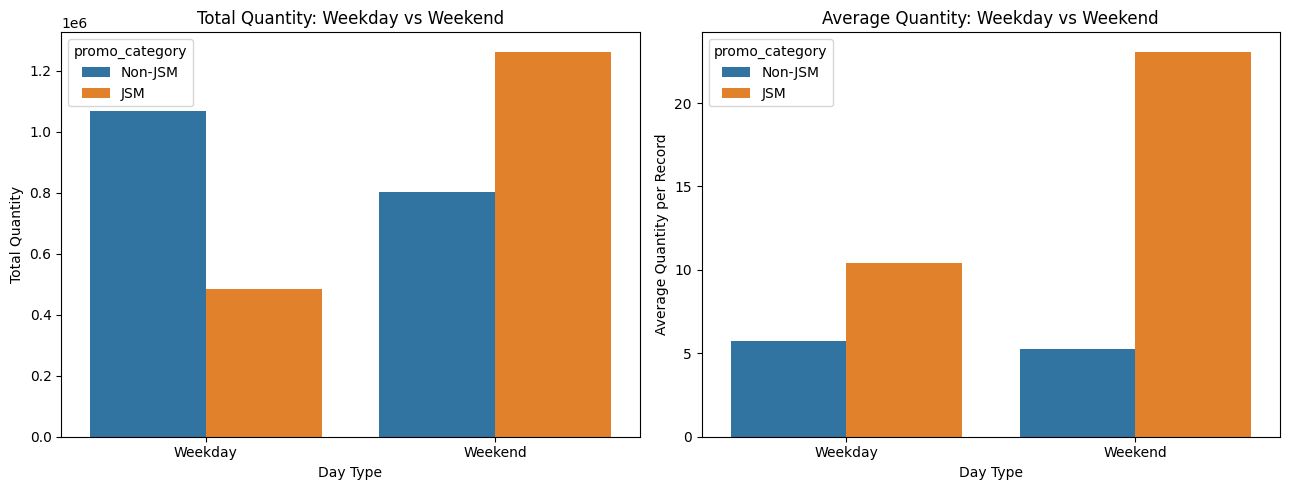

In [34]:
# Membuat kategori weekday dan weekend
df_analysis['day_type'] = df_analysis['trx_time'].dt.dayofweek.map(
    lambda x: 'Weekend' if x >= 4 else 'Weekday'
)

# Mengelompokkan performa penjualan
weekend_analysis = (
    df_analysis
    .groupby(['day_type', 'is_jsm_promo'])
    .agg(
        total_records=('receipt_id', 'count'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum'),
        avg_quantity=('qty', 'mean'),
        avg_sales=('total_price', 'mean')
    )
    .reset_index()
)

# Memberikan label kategori promo
weekend_analysis['promo_category'] = (
    weekend_analysis['is_jsm_promo']
    .map({1: 'JSM', 0: 'Non-JSM'})
)

# Mengurutkan hasil
weekend_analysis['day_type'] = pd.Categorical(
    weekend_analysis['day_type'],
    categories=['Weekday', 'Weekend'],
    ordered=True
)

weekend_analysis = weekend_analysis.sort_values(
    ['day_type', 'is_jsm_promo']
)

display(weekend_analysis)

# Mengambil data JSM saja
jsm_comparison = weekend_analysis[
    weekend_analysis['is_jsm_promo'] == 1
].set_index('day_type')

# Menghitung persentase perubahan Weekend terhadap Weekday
metrics = [
    'total_records',
    'total_quantity',
    'total_sales',
    'avg_quantity',
    'avg_sales'
]

comparison_result = pd.DataFrame({
    'weekday': jsm_comparison.loc['Weekday', metrics],
    'weekend': jsm_comparison.loc['Weekend', metrics]
})

comparison_result['increase_pct'] = (
    (comparison_result['weekend'] - comparison_result['weekday'])
    / comparison_result['weekday'] * 100
)

display(comparison_result)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Perbandingan quantity
sns.barplot(
    data=weekend_analysis,
    x='day_type',
    y='total_quantity',
    hue='promo_category',
    ax=axes[0]
)

axes[0].set_title('Total Quantity: Weekday vs Weekend')
axes[0].set_xlabel('Day Type')
axes[0].set_ylabel('Total Quantity')

# Perbandingan average quantity
sns.barplot(
    data=weekend_analysis,
    x='day_type',
    y='avg_quantity',
    hue='promo_category',
    ax=axes[1]
)

axes[1].set_title('Average Quantity: Weekday vs Weekend')
axes[1].set_xlabel('Day Type')
axes[1].set_ylabel('Average Quantity per Record')

plt.tight_layout()
plt.show()

In [35]:
# Menghitung total quantity per tanggal dan kategori promo
daily_quantity = (
    df_analysis
    .groupby([
        df_analysis['trx_time'].dt.date,
        'day_type',
        'is_jsm_promo'
    ])
    .agg(total_quantity=('qty', 'sum'))
    .reset_index()
)

# Menghitung rata-rata quantity per hari
daily_average = (
    daily_quantity
    .groupby(['day_type', 'is_jsm_promo'])
    .agg(
        avg_daily_quantity=('total_quantity', 'mean')
    )
    .reset_index()
)

daily_average['promo_category'] = (
    daily_average['is_jsm_promo']
    .map({1: 'JSM', 0: 'Non-JSM'})
)

display(daily_average)

,day_type,is_jsm_promo,avg_daily_quantity,promo_category
0,Weekday,0,"1,033.92",Non-JSM
1,Weekday,1,472.27,JSM
2,Weekend,0,"1,039.51",Non-JSM
3,Weekend,1,"1,623.43",JSM


Berdasarkan analisis weekday dan weekend, produk JSM menunjukkan peningkatan aktivitas penjualan yang lebih tinggi pada akhir pekan. Total quantity meningkat sebesar 160,66%, sementara rata-rata quantity per record meningkat sebesar 121,65% dibandingkan hari kerja. Sebaliknya, rata-rata quantity produk Non-JSM relatif stabil. Temuan ini mengindikasikan adanya perbedaan pola pembelian produk JSM pada periode weekend yang perlu ditelusuri lebih lanjut untuk mengidentifikasi SKU dan karakteristik pembelian dengan kuantitas tinggi.

### **2. Product & Bulk Transaction Analysis**

Mengidentifikasi SKU dengan aktivitas penjualan tinggi dan transaksi yang memiliki kuantitas di atas batas statistik per SKU.

In [36]:
# Mengambil transaksi produk JSM
df_jsm = df_analysis[
    df_analysis['is_jsm_promo'] == 1
].copy()

# Menghitung performa setiap SKU
sku_performance = (
    df_jsm
    .groupby(['sku_id', 'product_name'])
    .agg(
        total_records=('receipt_id', 'count'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum')
    )
    .reset_index()
)

# Menghitung kontribusi quantity
sku_performance['quantity_contribution_pct'] = (
    sku_performance['total_quantity']
    / sku_performance['total_quantity'].sum() * 100
)

# Mengurutkan berdasarkan quantity tertinggi
top_10_sku = (
    sku_performance
    .sort_values('total_quantity', ascending=False)
    .head(10)
)

display(top_10_sku)

# Membandingkan performa SKU JSM berdasarkan weekday dan weekend

sku_day_performance = (
    df_jsm
    .groupby(['sku_id', 'product_name', 'day_type'])
    .agg(
        total_records=('receipt_id', 'count'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum'),
        avg_quantity=('qty', 'mean')
    )
    .reset_index()
)

# Membuat perbandingan weekday dan weekend
sku_day_pivot = sku_day_performance.pivot(
    index=['sku_id', 'product_name'],
    columns='day_type',
    values=['total_quantity', 'avg_quantity', 'total_sales']
).fillna(0)

# Merapikan nama kolom
sku_day_pivot.columns = [
    f'{metric}_{day.lower()}'
    for metric, day in sku_day_pivot.columns
]

sku_day_pivot = sku_day_pivot.reset_index()

# Menghitung persentase peningkatan rata-rata quantity
sku_day_pivot['avg_qty_increase_pct'] = (
    (
        sku_day_pivot['avg_quantity_weekend']
        - sku_day_pivot['avg_quantity_weekday']
    )
    / sku_day_pivot['avg_quantity_weekday'].replace(0, np.nan)
) * 100

# Mengurutkan berdasarkan peningkatan rata-rata quantity
sku_day_pivot = sku_day_pivot.sort_values(
    'avg_qty_increase_pct',
    ascending=False
)

display(sku_day_pivot.head(10))


,sku_id,product_name,total_records,total_quantity,total_sales,quantity_contribution_pct
13,SKU000070,Pepsodent 190g,1082,31649,"532,906,190.00",1.81
66,SKU000351,Indomie Goreng,1134,30713,"224,069,760.00",1.76
49,SKU000272,Minyak Goreng Bimoli,1092,27229,"698,053,020.00",1.56
20,SKU000103,Air Mineral Aqua,1197,26149,"491,986,600.00",1.50
80,SKU000448,Indomie Goreng,1046,26096,"614,953,381.00",1.49
23,SKU000131,Minyak Goreng Bimoli,1108,26032,"976,028,115.00",1.49
37,SKU000211,Pepsodent 190g,1084,25469,"657,330,048.00",1.46
88,SKU000486,Minyak Goreng Bimoli,1113,25403,"589,986,976.00",1.45
72,SKU000402,Bimoli Pouch 2000ml,1156,25026,"431,365,092.00",1.43
86,SKU000482,Indomie Goreng,1104,23917,"364,812,266.00",1.37


/tmp/ipykernel_457/2154852276.py:52: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ).fillna(0)


,sku_id,product_name,total_quantity_weekday,total_quantity_weekend,avg_quantity_weekday,avg_quantity_weekend,total_sales_weekday,total_sales_weekend,avg_qty_increase_pct
66,SKU000351,Indomie Goreng,4275,26438,8.19,43.20,"38,475,000.00","185,594,760.00",427.49
20,SKU000103,Air Mineral Aqua,4154,21995,7.54,34.05,"116,312,000.00","375,674,600.00",351.62
88,SKU000486,Minyak Goreng Bimoli,3917,21486,7.80,35.17,"127,694,200.00","462,292,776.00",350.68
61,SKU000340,Indomie Goreng,3650,17490,6.87,29.39,"136,875,000.00","432,877,500.00",327.64
3,SKU000012,Pepsodent 190g,3960,17260,7.50,31.50,"51,480,000.00","181,747,800.00",319.95
76,SKU000438,Pepsodent 190g,3622,18674,7.23,29.93,"25,354,000.00","103,267,220.00",313.94
5,SKU000022,Minyak Bimoli 2L,4006,16408,7.70,28.59,"163,044,200.00","534,244,480.00",271.05
73,SKU000406,Indomie Goreng,4401,19152,8.53,31.24,"185,722,200.00","493,010,784.00",266.31
78,SKU000445,Aqua 600ml,3558,14282,6.86,22.49,"120,616,200.00","334,070,262.00",228.08
1,SKU000002,Indomie Goreng,4904,16986,9.12,29.44,"191,256,000.00","437,219,640.00",222.96


In [37]:

# Mengambil transaksi JSM pada weekend
df_jsm_weekend = df_jsm[
    df_jsm['day_type'] == 'Weekend'
].copy()

# Menghitung batas outlier quantity per SKU
sku_threshold = (
    df_jsm_weekend
    .groupby('sku_id')['qty']
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

sku_threshold['IQR'] = (
    sku_threshold['Q3'] - sku_threshold['Q1']
)

sku_threshold['upper_bound'] = (
    sku_threshold['Q3'] + 1.5 * sku_threshold['IQR']
)

# Menggabungkan batas outlier ke transaksi
df_bulk_check = df_jsm_weekend.merge(
    sku_threshold[['sku_id', 'upper_bound']],
    on='sku_id',
    how='left'
)

# Mengidentifikasi transaksi dengan quantity di atas batas
df_bulk_check['is_bulk_purchase'] = (
    df_bulk_check['qty'] > df_bulk_check['upper_bound']
)

# Ringkasan transaksi bulk purchase per SKU
bulk_summary = (
    df_bulk_check[
        df_bulk_check['is_bulk_purchase']
    ]
    .groupby(['sku_id', 'product_name'])
    .agg(
        total_bulk_records=('receipt_id', 'count'),
        total_bulk_quantity=('qty', 'sum'),
        max_quantity=('qty', 'max')
    )
    .reset_index()
    .sort_values('total_bulk_records', ascending=False)
)

display(bulk_summary.head(10))


,sku_id,product_name,total_bulk_records,total_bulk_quantity,max_quantity
11,SKU000119,Minyak Bimoli 2L,46,3692,89
21,SKU000291,Indomie Goreng,33,2728,88
19,SKU000264,Indomie Goreng,33,2680,89
0,SKU000001,Air Mineral Aqua,29,5054,2674
20,SKU000272,Minyak Goreng Bimoli,21,1781,89
24,SKU000314,Indomie Goreng,19,1636,89
15,SKU000211,Pepsodent 190g,19,1642,89
25,SKU000332,Minyak Bimoli 2L,14,1218,89
34,SKU000451,Indomie Goreng,13,1145,89
35,SKU000475,Indomie Goreng,12,1055,89


In [38]:
# Menampilkan 20 transaksi bulk purchase dengan quantity tertinggi

bulk_transactions = (
    df_bulk_check[
        df_bulk_check['is_bulk_purchase']
    ]
    .sort_values('qty', ascending=False)
    [[
        'receipt_id',
        'trx_time',
        'store_id',
        'sku_id',
        'product_name',
        'member_id',
        'qty',
        'upper_bound',
        'unit_price',
        'total_price'
    ]]
    .head(20)
)

display(bulk_transactions)


,receipt_id,trx_time,store_id,sku_id,product_name,member_id,qty,upper_bound,unit_price,total_price
39603,RCP00224382,2023-11-03 09:00:00+00:00,SAT-0445,SKU000351,Indomie Goreng,MEM-47311,8145,106.00,"9,000.00","57,177,900.00"
52721,RCP00089380,2021-05-30 19:00:00+00:00,SAT-0346,SKU000486,Minyak Goreng Bimoli,MEM-23160,7988,99.50,"32,600.00","171,869,808.00"
12201,RCP00219768,2023-10-21 19:00:00+00:00,SAT-0939,SKU000103,Air Mineral Aqua,MEM-04143,6781,107.00,"28,000.00","115,819,480.00"
43760,RCP00283870,2021-09-05 18:00:00+00:00,SAT-0859,SKU000406,Indomie Goreng,None,5491,104.50,"42,200.00","141,349,322.00"
39602,RCP00203861,2023-06-17 14:00:00+00:00,SAT-0461,SKU000351,Indomie Goreng,None,5088,106.00,"9,000.00","35,717,760.00"
2286,RCP00247636,2023-06-11 11:00:00+00:00,SAT-0657,SKU000012,Pepsodent 190g,None,5087,99.50,"13,000.00","53,566,110.00"
9255,RCP00000726,2024-02-17 10:00:00+00:00,SAT-0016,SKU000076,Aqua 600ml,MEM-22797,5021,94.50,"4,300.00","13,385,986.00"
45547,RCP00171355,2025-02-09 18:00:00+00:00,SAT-0284,SKU000438,Pepsodent 190g,MEM-41426,4994,99.50,"7,000.00","27,616,820.00"
3450,RCP00243571,2021-01-01 12:00:00+00:00,SAT-0769,SKU000022,Minyak Bimoli 2L,MEM-22019,4545,96.00,"40,700.00","147,985,200.00"
36565,RCP00230713,2022-05-13 08:00:00+00:00,SAT-0641,SKU000340,Indomie Goreng,MEM-28512,4536,99.75,"37,500.00","112,266,000.00"


In [39]:

# Mengambil transaksi bulk yang memiliki member_id
df_bulk_member = df_bulk_check[
    (df_bulk_check['is_bulk_purchase']) &
    (df_bulk_check['member_id'].notna())
].copy()

# Menghitung pola pembelian per pelanggan
customer_bulk_summary = (
    df_bulk_member
    .groupby('member_id')
    .agg(
        total_bulk_transactions=('receipt_id', 'nunique'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum'),
        total_sku=('sku_id', 'nunique'),
        total_store=('store_id', 'nunique'),
        first_transaction=('trx_time', 'min'),
        last_transaction=('trx_time', 'max')
    )
    .reset_index()
    .sort_values(
        ['total_bulk_transactions', 'total_quantity'],
        ascending=False
    )
)

display(customer_bulk_summary.head(20))


# Menghitung transaksi bulk tanpa identitas member
bulk_without_member = df_bulk_check[
    (df_bulk_check['is_bulk_purchase']) &
    (df_bulk_check['member_id'].isna())
]

print("Jumlah transaksi bulk tanpa member ID:",
      bulk_without_member['receipt_id'].nunique())

print("Total quantity:",
      bulk_without_member['qty'].sum())

print("Total nilai transaksi:",
      bulk_without_member['total_price'].sum())

,member_id,total_bulk_transactions,total_quantity,total_sales,total_sku,total_store,first_transaction,last_transaction
213,MEM-47311,1,8145,"57,177,900.00",1,1,2023-11-03 09:00:00+00:00,2023-11-03 09:00:00+00:00
98,MEM-23160,1,7988,"171,869,808.00",1,1,2021-05-30 19:00:00+00:00,2021-05-30 19:00:00+00:00
18,MEM-04143,1,6781,"115,819,480.00",1,1,2023-10-21 19:00:00+00:00,2023-10-21 19:00:00+00:00
97,MEM-22797,1,5021,"13,385,986.00",1,1,2024-02-17 10:00:00+00:00,2024-02-17 10:00:00+00:00
184,MEM-41426,1,4994,"27,616,820.00",1,1,2025-02-09 18:00:00+00:00,2025-02-09 18:00:00+00:00
94,MEM-22019,1,4545,"147,985,200.00",1,1,2021-01-01 12:00:00+00:00,2021-01-01 12:00:00+00:00
123,MEM-28512,1,4536,"112,266,000.00",1,1,2022-05-13 08:00:00+00:00,2022-05-13 08:00:00+00:00
188,MEM-42150,1,3431,"88,313,940.00",1,1,2025-05-09 19:00:00+00:00,2025-05-09 19:00:00+00:00
195,MEM-44168,1,2674,"22,325,226.00",1,1,2022-08-14 10:00:00+00:00,2022-08-14 10:00:00+00:00
79,MEM-18312,1,1592,"5,271,112.00",1,1,2023-01-06 17:00:00+00:00,2023-01-06 17:00:00+00:00


Jumlah transaksi bulk tanpa member ID: 77
Total quantity: 25522
Total nilai transaksi: 382053986.0


In [40]:

# Menghitung distribusi frekuensi transaksi bulk per pelanggan

customer_frequency = (
    customer_bulk_summary
    .groupby('total_bulk_transactions')
    .agg(
        total_customers=('member_id', 'count'),
        total_quantity=('total_quantity', 'sum'),
        total_sales=('total_sales', 'sum')
    )
    .reset_index()
    .sort_values('total_bulk_transactions')
)

display(customer_frequency)

# Menghitung jumlah pelanggan dengan transaksi bulk berulang
repeat_customers = customer_bulk_summary[
    customer_bulk_summary['total_bulk_transactions'] > 1
]

print("Total pelanggan dengan transaksi bulk:",
      customer_bulk_summary['member_id'].nunique())

print("Pelanggan dengan transaksi bulk berulang:",
      repeat_customers['member_id'].nunique())

print("Total transaksi bulk berulang:",
      repeat_customers['total_bulk_transactions'].sum())

display(
    repeat_customers.sort_values(
        'total_bulk_transactions',
        ascending=False
    ).head(20)
)


,total_bulk_transactions,total_customers,total_quantity,total_sales
0,1,219,74931,"1,232,838,199.00"


Total pelanggan dengan transaksi bulk: 219
Pelanggan dengan transaksi bulk berulang: 0
Total transaksi bulk berulang: 0


,member_id,total_bulk_transactions,total_quantity,total_sales,total_sku,total_store,first_transaction,last_transaction


In [41]:

# Mengambil seluruh transaksi bulk JSM weekend
df_bulk_sales = df_bulk_check[
    df_bulk_check['is_bulk_purchase']
].copy()

# Menghitung total penjualan JSM weekend
total_jsm_weekend_sales = df_jsm_weekend['total_price'].sum()

# Menghitung ringkasan transaksi bulk
total_bulk_records = df_bulk_sales['receipt_id'].nunique()
total_bulk_quantity = df_bulk_sales['qty'].sum()
total_bulk_sales = df_bulk_sales['total_price'].sum()

# Menghitung kontribusi nilai transaksi bulk
bulk_sales_contribution = (
    total_bulk_sales / total_jsm_weekend_sales * 100
)

print("Total transaksi bulk:", total_bulk_records)
print("Total quantity bulk:", f"{total_bulk_quantity:,.0f}")
print("Total nilai transaksi bulk:",
      f"Rp{total_bulk_sales:,.2f}")
print("Total penjualan JSM weekend:",
      f"Rp{total_jsm_weekend_sales:,.2f}")
print("Kontribusi penjualan bulk:",
      f"{bulk_sales_contribution:.2f}%")

# Ringkasan transaksi bulk berdasarkan SKU
bulk_sku_sales = (
    df_bulk_sales
    .groupby(['sku_id', 'product_name'])
    .agg(
        total_records=('receipt_id', 'nunique'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum')
    )
    .reset_index()
)

bulk_sku_sales['sales_contribution_pct'] = (
    bulk_sku_sales['total_sales']
    / total_bulk_sales * 100
)

bulk_sku_sales = bulk_sku_sales.sort_values(
    'total_sales',
    ascending=False
)

display(bulk_sku_sales.head(10))


Total transaksi bulk: 296
Total quantity bulk: 100,453
Total nilai transaksi bulk: Rp1,614,892,185.00
Total penjualan JSM weekend: Rp21,222,512,458.00
Kontribusi penjualan bulk: 7.61%


,sku_id,product_name,total_records,total_quantity,total_sales,sales_contribution_pct
38,SKU000486,Minyak Goreng Bimoli,1,7988,"171,869,808.00",10.64
3,SKU000022,Minyak Bimoli 2L,1,4545,"147,985,200.00",9.16
30,SKU000406,Indomie Goreng,1,5491,"141,349,322.00",8.75
10,SKU000103,Air Mineral Aqua,1,6781,"115,819,480.00",7.17
1,SKU000002,Indomie Goreng,2,4430,"114,028,200.00",7.06
26,SKU000340,Indomie Goreng,1,4536,"112,266,000.00",6.95
28,SKU000351,Indomie Goreng,2,13233,"92,895,660.00",5.75
11,SKU000119,Minyak Bimoli 2L,46,3692,"84,354,816.00",5.22
21,SKU000291,Indomie Goreng,33,2728,"66,639,584.00",4.13
19,SKU000264,Indomie Goreng,33,2680,"61,280,880.00",3.79


In [42]:

# Memeriksa jumlah transaksi dan pelanggan bulk

print(
    "Total baris transaksi bulk:",
    len(df_bulk_sales)
)

print(
    "Total receipt unik:",
    df_bulk_sales['receipt_id'].nunique()
)

print(
    "Total pelanggan unik:",
    df_bulk_sales['member_id'].nunique()
)

print(
    "Transaksi tanpa member ID:",
    df_bulk_sales['member_id'].isna().sum()
)

# Menghitung transaksi bulk berulang per pelanggan
bulk_customer_check = (
    df_bulk_sales
    .dropna(subset=['member_id'])
    .groupby('member_id')
    .agg(
        total_bulk_transactions=('receipt_id', 'nunique'),
        total_quantity=('qty', 'sum'),
        total_sales=('total_price', 'sum')
    )
    .reset_index()
)

repeat_customers = bulk_customer_check[
    bulk_customer_check['total_bulk_transactions'] > 1
]

print(
    "Pelanggan dengan transaksi bulk berulang:",
    len(repeat_customers)
)


Total baris transaksi bulk: 296
Total receipt unik: 296
Total pelanggan unik: 219
Transaksi tanpa member ID: 77
Pelanggan dengan transaksi bulk berulang: 0


Ditemukan 296 transaksi bulk dengan total kuantitas 100.453 unit dan nilai penjualan Rp1,61 miliar, atau berkontribusi sebesar 7,61% terhadap total penjualan Promo JSM weekend. Transaksi bulk terkonsentrasi pada beberapa SKU, terutama produk minyak goreng, Indomie, dan Aqua.

Dari 219 pelanggan yang teridentifikasi, tidak ditemukan transaksi bulk berulang. Namun, terdapat 77 transaksi tanpa Member ID sehingga pola pembelian pelanggan belum dapat dianalisis secara menyeluruh.

Temuan ini menunjukkan perlunya evaluasi batas kuantitas pembelian berdasarkan karakteristik masing-masing SKU untuk mendukung efektivitas Promo JSM dan menjaga ketersediaan produk.

**Catatan pembacaan:** total quantity 100.453 unit merupakan jumlah quantity penuh pada transaksi yang terindikasi bulk, sedangkan 76.760 unit pada analisis lanjutan merupakan *excess quantity* (selisih quantity terhadap kandidat batas IQR). Kedua angka menggunakan definisi yang berbeda.

### **3. Candidate Purchase Limit using IQR**

Menentukan kandidat batas pembelian per SKU menggunakan Q3 + 1,5 × IQR pada transaksi Promo JSM hari Jumat–Minggu yang berstatus COMPLETED dan memiliki quantity positif.

In [43]:

# 1. Menyiapkan transaksi JSM pada hari Jumat-Minggu

df_simulation = df_merged.copy()

df_simulation['trx_time'] = pd.to_datetime(
    df_simulation['trx_time']
)

df_simulation['day_name'] = df_simulation['trx_time'].dt.day_name()

df_simulation = df_simulation[
    (df_simulation['is_jsm_promo'] == 1) &
    (df_simulation['day_name'].isin(['Friday', 'Saturday', 'Sunday'])) &
    (df_simulation['transaction_status'] == 'COMPLETED') &
    (df_simulation['qty'] > 0)
].copy()


# 2. Menghitung Q1, Q3, IQR, dan upper bound per SKU

sku_limit = (
    df_simulation
    .groupby(['sku_id', 'product_name'])['qty']
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

sku_limit['IQR'] = sku_limit['Q3'] - sku_limit['Q1']

sku_limit['upper_bound'] = (
    sku_limit['Q3'] + (1.5 * sku_limit['IQR'])
)

# Membulatkan batas ke bilangan bulat
sku_limit['candidate_limit'] = (
    sku_limit['upper_bound'].apply(np.floor).astype(int)
)

# Menampilkan hasil
sku_limit = sku_limit.sort_values(
    'candidate_limit',
    ascending=False
)

display(sku_limit.head(20))


# 1. Menggabungkan kandidat batas pembelian ke data transaksi

df_impact = df_simulation.merge(
    sku_limit[['sku_id', 'candidate_limit']],
    on='sku_id',
    how='left'
)

# 2. Menghitung quantity yang melebihi batas

df_impact['excess_qty'] = (
    df_impact['qty'] - df_impact['candidate_limit']
).clip(lower=0)

# 3. Menghitung estimasi nilai penjualan dari quantity berlebih

df_impact['excess_sales'] = (
    df_impact['excess_qty'] * df_impact['unit_price']
)

# 4. Mengidentifikasi transaksi yang melebihi batas

df_affected = df_impact[
    df_impact['excess_qty'] > 0
].copy()

# 5. Membuat ringkasan dampak per SKU

impact_summary = (
    df_affected
    .groupby(['sku_id', 'product_name'])
    .agg(
        total_affected_transactions=('receipt_id', 'nunique'),
        total_excess_quantity=('excess_qty', 'sum'),
        estimated_excess_sales=('excess_sales', 'sum'),
        max_quantity=('qty', 'max'),
        candidate_limit=('candidate_limit', 'first')
    )
    .reset_index()
    .sort_values(
        'total_excess_quantity',
        ascending=False
    )
)

display(impact_summary.head(20))

# 6. Ringkasan dampak keseluruhan

total_transactions = len(df_impact)
affected_transactions = len(df_affected)

print("Total transaksi JSM weekend:", total_transactions)
print("Transaksi melebihi kandidat batas:", affected_transactions)

print(
    "Persentase transaksi terdampak:",
    round(affected_transactions / total_transactions * 100, 2),
    "%"
)

print(
    "Total quantity berlebih:",
    df_affected['excess_qty'].sum()
)

print(
    "Estimasi nilai penjualan quantity berlebih: Rp",
    f"{df_affected['excess_sales'].sum():,.2f}"
)


,sku_id,product_name,Q1,Q3,IQR,upper_bound,candidate_limit
91,SKU000502,Beras Premium 5kg,4.00,60.00,56.00,144.00,144
92,SKU000504,Kopi Kapal Api Sachet,4.00,59.00,55.00,141.50,141
93,SKU000507,Mie Sedaap Goreng,4.00,59.00,55.00,141.50,141
90,SKU000501,Teh Pucuk Harum 350ml,4.00,57.75,53.75,138.38,138
38,SKU000214,Bimoli Pouch 2000ml,2.00,48.00,46.00,117.00,117
70,SKU000376,Minyak Goreng Bimoli,2.00,47.00,45.00,114.50,114
26,SKU000144,Indomie Goreng,2.00,46.50,44.50,113.25,113
41,SKU000221,Pepsodent 190g,1.00,44.00,43.00,108.50,108
30,SKU000163,Pepsodent 190g,2.00,44.00,42.00,107.00,107
20,SKU000103,Air Mineral Aqua,2.00,44.00,42.00,107.00,107


,sku_id,product_name,total_affected_transactions,total_excess_quantity,estimated_excess_sales,max_quantity,candidate_limit
28,SKU000351,Indomie Goreng,2,13021,"117,189,000.00",8145,106
38,SKU000486,Minyak Goreng Bimoli,1,7889,"257,181,400.00",7988,99
10,SKU000103,Air Mineral Aqua,1,6674,"186,872,000.00",6781,107
30,SKU000406,Indomie Goreng,1,5387,"227,331,400.00",5491,104
2,SKU000012,Pepsodent 190g,1,4988,"64,844,000.00",5087,99
9,SKU000076,Aqua 600ml,1,4927,"21,186,100.00",5021,94
31,SKU000438,Pepsodent 190g,1,4895,"34,265,000.00",4994,99
3,SKU000022,Minyak Bimoli 2L,1,4449,"181,074,300.00",4545,96
26,SKU000340,Indomie Goreng,1,4437,"166,387,500.00",4536,99
1,SKU000002,Indomie Goreng,2,4228,"164,892,000.00",3431,101


Total transaksi JSM weekend: 54717
Transaksi melebihi kandidat batas: 296
Persentase transaksi terdampak: 0.54 %
Total quantity berlebih: 76760
Estimasi nilai penjualan quantity berlebih: Rp 1,709,993,400.00


In [44]:
df_impact['excess_sales'] = (
    df_impact['excess_qty'] * df_impact['unit_price']
)


# Menghitung harga aktual per unit setelah diskon

df_impact['actual_unit_price'] = (
    df_impact['total_price'] / df_impact['qty']
)

# Mengestimasi nilai penjualan dari quantity berlebih

df_impact['excess_sales_adjusted'] = (
    df_impact['excess_qty'] *
    df_impact['actual_unit_price']
)

# Total estimasi nilai penjualan quantity berlebih

total_excess_sales_adjusted = (
    df_impact['excess_sales_adjusted'].sum()
)

print(
    "Estimasi nilai penjualan quantity berlebih setelah diskon: Rp",
    f"{total_excess_sales_adjusted:,.2f}"
)


Estimasi nilai penjualan quantity berlebih setelah diskon: Rp 1,175,916,383.00


Simulasi menggunakan kandidat batas IQR menunjukkan bahwa 296 transaksi atau 0,54% dari total transaksi JSM weekend memiliki quantity di atas batas statistik SKU masing-masing. Transaksi tersebut mencakup 76.760 unit quantity berlebih dengan estimasi nilai penjualan setelah diskon sebesar Rp1,18 miliar.

### **4. Restriction Scenario Simulation**

Membandingkan skenario batas seragam 10, 20, dan 30 unit dengan kandidat batas IQR per SKU.

,scenario,total_transactions,affected_transactions,affected_pct,total_excess_quantity,estimated_excess_sales
0,Limit 10,54717,22779,41.63,961328,"16,116,793,881.00"
1,Limit 20,54717,20161,36.85,746204,"12,481,124,875.00"
2,Limit 30,54717,16291,29.77,563997,"9,400,621,084.00"
3,IQR per SKU,54717,296,0.54,76760,"1,175,916,383.00"


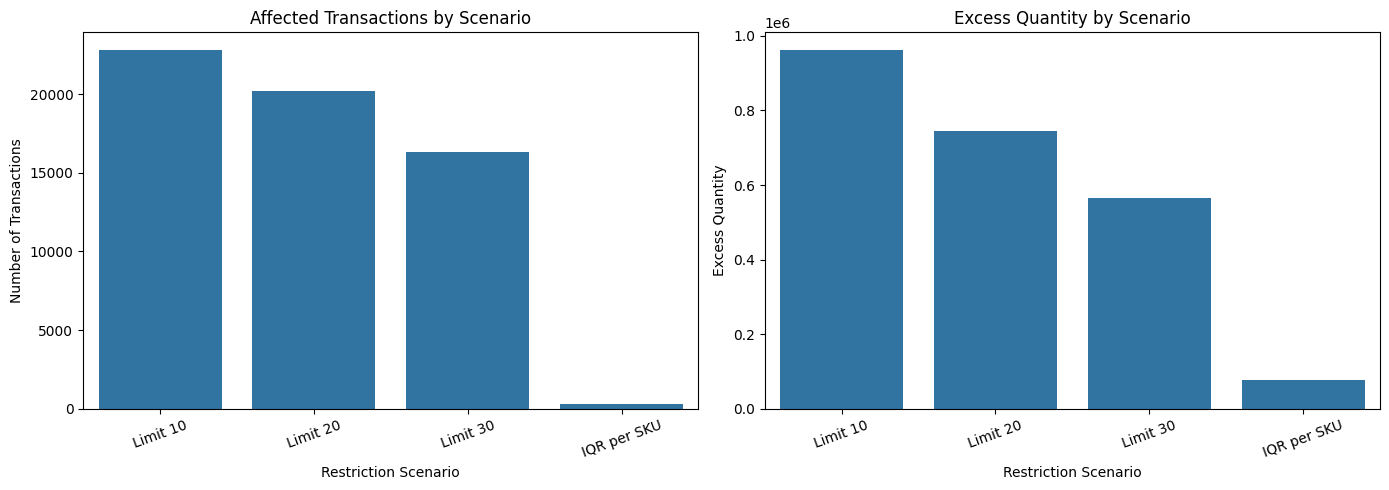

In [45]:

# Membuat salinan data transaksi JSM weekend
df_scenario = df_simulation.copy()

# Menggabungkan batas IQR setiap SKU
df_scenario = df_scenario.merge(
    sku_limit[['sku_id', 'candidate_limit']],
    on='sku_id',
    how='left'
)

# Menghitung harga aktual per unit setelah diskon
df_scenario['actual_unit_price'] = (
    df_scenario['total_price'] / df_scenario['qty']
)

# Menentukan skenario pembatasan
scenarios = {
    'Limit 10': 10,
    'Limit 20': 20,
    'Limit 30': 30,
    'IQR per SKU': 'candidate_limit'
}

results = []

for scenario_name, limit in scenarios.items():

    if limit == 'candidate_limit':
        df_scenario['limit'] = df_scenario['candidate_limit']
    else:
        df_scenario['limit'] = limit

    # Menghitung quantity yang melebihi batas
    excess_qty = (
        df_scenario['qty'] - df_scenario['limit']
    ).clip(lower=0)

    # Menghitung estimasi nilai penjualan quantity berlebih
    excess_sales = (
        excess_qty * df_scenario['actual_unit_price']
    )

    # Mengidentifikasi transaksi terdampak
    affected = excess_qty > 0

    results.append({
        'scenario': scenario_name,
        'total_transactions': len(df_scenario),
        'affected_transactions': affected.sum(),
        'affected_pct': (
            affected.sum() / len(df_scenario) * 100
        ),
        'total_excess_quantity': excess_qty.sum(),
        'estimated_excess_sales': excess_sales.sum()
    })

# Membuat tabel perbandingan
scenario_comparison = pd.DataFrame(results)

display(
    scenario_comparison.round(2)
)


import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik transaksi terdampak
sns.barplot(
    data=scenario_comparison,
    x='scenario',
    y='affected_transactions',
    ax=axes[0]
)

axes[0].set_title('Affected Transactions by Scenario')
axes[0].set_xlabel('Restriction Scenario')
axes[0].set_ylabel('Number of Transactions')
axes[0].tick_params(axis='x', rotation=20)

# Grafik quantity berlebih
sns.barplot(
    data=scenario_comparison,
    x='scenario',
    y='total_excess_quantity',
    ax=axes[1]
)

axes[1].set_title('Excess Quantity by Scenario')
axes[1].set_xlabel('Restriction Scenario')
axes[1].set_ylabel('Excess Quantity')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


Berdasarkan simulasi awal, skenario IQR per SKU menjadi kandidat paling relevan untuk diteliti lebih lanjut karena menghasilkan jumlah transaksi terdampak yang jauh lebih kecil.

Namun, batas IQR belum bisa langsung ditetapkan sebagai kebijakan final. Batas tersebut masih perlu diuji berdasarkan pola pembelian pelanggan, kewajaran jumlah pembelian, serta karakteristik produk.

### **5. Customer Behavior Analysis**

Menganalisis frekuensi transaksi berlebih, riwayat pembelian pelanggan, jarak waktu antartransaksi, dan konsentrasi quantity berlebih.

In [46]:

# 1. Memisahkan transaksi yang memiliki member ID
df_customer_affected = df_affected[
    df_affected['member_id'].notna()
].copy()

# 2. Mengelompokkan transaksi berdasarkan pelanggan
customer_summary = (
    df_customer_affected
    .groupby('member_id')
    .agg(
        total_affected_transactions=('receipt_id', 'nunique'),
        total_excess_quantity=('excess_qty', 'sum'),
        estimated_excess_sales=('excess_sales', 'sum'),
        total_sku=('sku_id', 'nunique'),
        total_store=('store_id', 'nunique'),
        first_transaction=('trx_time', 'min'),
        last_transaction=('trx_time', 'max')
    )
    .reset_index()
    .sort_values(
        ['total_affected_transactions', 'total_excess_quantity'],
        ascending=False
    )
)

# 3. Menampilkan 20 pelanggan dengan transaksi berlebih terbanyak
display(customer_summary.head(20))

# 4. Ringkasan pelanggan
print("Total pelanggan dengan transaksi berlebih:",
      customer_summary['member_id'].nunique())

print("Pelanggan dengan transaksi berlebih berulang:",
      (customer_summary['total_affected_transactions'] > 1).sum())

print("Total transaksi berlebih dengan member ID:",
      customer_summary['total_affected_transactions'].sum())

# 5. Transaksi tanpa member ID
print("Transaksi berlebih tanpa member ID:",
      df_affected['member_id'].isna().sum())


,member_id,total_affected_transactions,total_excess_quantity,estimated_excess_sales,total_sku,total_store,first_transaction,last_transaction
213,MEM-47311,1,8039,"72,351,000.00",1,1,2023-11-03 09:00:00+00:00,2023-11-03 09:00:00+00:00
98,MEM-23160,1,7889,"257,181,400.00",1,1,2021-05-30 19:00:00+00:00,2021-05-30 19:00:00+00:00
18,MEM-04143,1,6674,"186,872,000.00",1,1,2023-10-21 19:00:00+00:00,2023-10-21 19:00:00+00:00
97,MEM-22797,1,4927,"21,186,100.00",1,1,2024-02-17 10:00:00+00:00,2024-02-17 10:00:00+00:00
184,MEM-41426,1,4895,"34,265,000.00",1,1,2025-02-09 18:00:00+00:00,2025-02-09 18:00:00+00:00
94,MEM-22019,1,4449,"181,074,300.00",1,1,2021-01-01 12:00:00+00:00,2021-01-01 12:00:00+00:00
123,MEM-28512,1,4437,"166,387,500.00",1,1,2022-05-13 08:00:00+00:00,2022-05-13 08:00:00+00:00
188,MEM-42150,1,3330,"129,870,000.00",1,1,2025-05-09 19:00:00+00:00,2025-05-09 19:00:00+00:00
195,MEM-44168,1,2595,"31,399,500.00",1,1,2022-08-14 10:00:00+00:00,2022-08-14 10:00:00+00:00
79,MEM-18312,1,1504,"6,467,200.00",1,1,2023-01-06 17:00:00+00:00,2023-01-06 17:00:00+00:00


Total pelanggan dengan transaksi berlebih: 219
Pelanggan dengan transaksi berlebih berulang: 0
Total transaksi berlebih dengan member ID: 219
Transaksi berlebih tanpa member ID: 77


In [47]:

# Mengambil daftar pelanggan yang pernah memiliki transaksi berlebih
affected_members = df_customer_affected['member_id'].unique()

# Mengambil seluruh riwayat transaksi JSM weekend mereka
df_member_history = df_simulation[
    df_simulation['member_id'].isin(affected_members)
].copy()

# Mengelompokkan seluruh riwayat transaksi per pelanggan
member_history_summary = (
    df_member_history
    .groupby('member_id')
    .agg(
        total_jsm_transactions=('receipt_id', 'nunique'),
        total_jsm_quantity=('qty', 'sum'),
        total_jsm_sales=('total_price', 'sum'),
        total_sku=('sku_id', 'nunique'),
        total_store=('store_id', 'nunique')
    )
    .reset_index()
)

# Menggabungkan dengan jumlah transaksi berlebih
member_history_summary = member_history_summary.merge(
    customer_summary[
        ['member_id', 'total_affected_transactions',
         'total_excess_quantity', 'estimated_excess_sales']
    ],
    on='member_id',
    how='left'
)

# Mengurutkan pelanggan berdasarkan frekuensi transaksi JSM
member_history_summary = member_history_summary.sort_values(
    'total_jsm_transactions',
    ascending=False
)

display(member_history_summary.head(20))

# Ringkasan pelanggan dengan transaksi JSM berulang
print(
    "Pelanggan dengan lebih dari 1 transaksi JSM:",
    (member_history_summary['total_jsm_transactions'] > 1).sum()
)

print(
    "Pelanggan dengan lebih dari 1 transaksi berlebih:",
    (member_history_summary['total_affected_transactions'] > 1).sum()
)


,member_id,total_jsm_transactions,total_jsm_quantity,total_jsm_sales,total_sku,total_store,total_affected_transactions,total_excess_quantity,estimated_excess_sales
1,MEM-00221,5,172,"2,865,746.00",5,5,1,1,"31,300.00"
81,MEM-18422,5,211,"4,138,858.00",5,5,1,16,"494,400.00"
53,MEM-10640,4,1021,"9,906,599.00",4,4,1,897,"11,840,400.00"
73,MEM-16299,4,103,"1,003,926.00",4,4,1,2,"24,200.00"
207,MEM-46765,4,96,"869,299.00",4,4,1,6,"72,600.00"
179,MEM-40571,4,1105,"21,883,040.00",4,4,1,910,"22,932,000.00"
99,MEM-23408,4,95,"1,666,697.00",4,4,1,6,"142,800.00"
28,MEM-06363,3,94,"1,511,022.00",3,3,1,1,"25,500.00"
40,MEM-08437,3,129,"2,067,486.00",3,3,1,10,"357,000.00"
72,MEM-16065,3,178,"1,998,052.00",2,3,1,2,"27,000.00"


Pelanggan dengan lebih dari 1 transaksi JSM: 112
Pelanggan dengan lebih dari 1 transaksi berlebih: 0


Dari 219 pelanggan yang teridentifikasi memiliki transaksi di atas batas IQR, sebanyak 112 pelanggan (51,14%) tercatat melakukan transaksi JSM lebih dari satu kali. Namun, tidak ditemukan pelanggan yang berulang kali melakukan transaksi di atas batas tersebut. Hal ini menunjukkan bahwa transaksi berlebih cenderung terjadi secara sporadis, meskipun sebagian pelanggan memiliki aktivitas pembelian JSM yang berulang.

In [48]:

# 1. Mengurutkan transaksi berdasarkan pelanggan dan waktu
df_member_timing = df_member_history.sort_values(
    ['member_id', 'trx_time']
).copy()

# 2. Menghitung jarak waktu antartransaksi dalam hari
df_member_timing['days_since_previous'] = (
    df_member_timing
    .groupby('member_id')['trx_time']
    .diff()
    .dt.total_seconds() / 86400
)

# 3. Menampilkan contoh hasil
display(
    df_member_timing[
        [
            'member_id',
            'receipt_id',
            'trx_time',
            'qty',
            'days_since_previous'
        ]
    ].head(20)
)


# 1. Mengambil transaksi yang memiliki transaksi sebelumnya
df_time_gap = df_member_timing[
    df_member_timing['days_since_previous'].notna()
].copy()

# 2. Membuat ringkasan jarak waktu per pelanggan
customer_timing_summary = (
    df_time_gap
    .groupby('member_id')
    .agg(
        total_transaction_intervals=('days_since_previous', 'count'),
        avg_days_between_transactions=('days_since_previous', 'mean'),
        min_days_between_transactions=('days_since_previous', 'min'),
        intervals_within_7_days=(
            'days_since_previous',
            lambda x: (x <= 7).sum()
        )
    )
    .reset_index()
)

# 3. Mengurutkan berdasarkan jarak transaksi terdekat
customer_timing_summary = customer_timing_summary.sort_values(
    ['min_days_between_transactions', 'intervals_within_7_days'],
    ascending=[True, False]
)

display(customer_timing_summary.head(20))

# 4. Ringkasan hasil
print(
    "Pelanggan dengan transaksi berjarak maksimal 7 hari:",
    (customer_timing_summary['intervals_within_7_days'] > 0).sum()
)

print(
    "Pelanggan dengan transaksi pada hari yang sama:",
    (customer_timing_summary['min_days_between_transactions'] == 0).sum()
)


,member_id,receipt_id,trx_time,qty,days_since_previous
246530,MEM-00042,RCP00311944,2022-06-03 20:00:00+00:00,88,NaN
51367,MEM-00221,RCP00054388,2021-11-06 08:00:00+00:00,1,NaN
191092,MEM-00221,RCP00326410,2022-10-08 00:00:00+00:00,85,335.67
213654,MEM-00221,RCP00314520,2023-06-11 00:00:00+00:00,4,246.00
377762,MEM-00221,RCP00271753,2023-07-28 10:00:00+00:00,3,47.42
364092,MEM-00221,RCP00322726,2023-10-28 00:00:00+00:00,79,91.58
263834,MEM-00250,RCP00322744,2025-03-01 08:00:00+00:00,75,NaN
246517,MEM-00440,RCP00330868,2021-09-05 15:00:00+00:00,82,NaN
263867,MEM-00844,RCP00302226,2025-02-14 17:00:00+00:00,87,NaN
436015,MEM-01183,RCP00324617,2023-05-13 00:00:00+00:00,67,NaN


,member_id,total_transaction_intervals,avg_days_between_transactions,min_days_between_transactions,intervals_within_7_days
93,MEM-40073,2,357.62,5.58,1
71,MEM-28980,2,447.96,7.00,1
110,MEM-47311,2,53.71,7.00,1
105,MEM-45425,1,7.50,7.50,0
36,MEM-16299,3,174.81,7.75,0
43,MEM-20304,2,73.38,14.08,0
50,MEM-22196,2,176.25,15.71,0
99,MEM-41887,2,44.92,28.71,0
2,MEM-01468,1,29.50,29.50,0
94,MEM-40074,2,216.92,36.04,0


Pelanggan dengan transaksi berjarak maksimal 7 hari: 3
Pelanggan dengan transaksi pada hari yang sama: 0


In [49]:

# Mengelompokkan jarak waktu antartransaksi

def categorize_gap(days):
    if days <= 7:
        return '0-7 hari'
    elif days <= 30:
        return '8-30 hari'
    else:
        return '>30 hari'

df_time_gap['gap_category'] = (
    df_time_gap['days_since_previous']
    .apply(categorize_gap)
)

# Menghitung jumlah interval pada setiap kategori
gap_distribution = (
    df_time_gap['gap_category']
    .value_counts()
    .reindex(['0-7 hari', '8-30 hari', '>30 hari'], fill_value=0)
    .reset_index()
)

gap_distribution.columns = [
    'rentang_jarak_transaksi',
    'total_intervals'
]

gap_distribution['percentage'] = (
    gap_distribution['total_intervals']
    / gap_distribution['total_intervals'].sum() * 100
)

display(gap_distribution)


,rentang_jarak_transaksi,total_intervals,percentage
0,0-7 hari,3,1.85
1,8-30 hari,6,3.70
2,>30 hari,153,94.44


Sebagian besar pelanggan dengan transaksi pembelian berlebih memiliki pola transaksi yang tidak berulang dalam waktu dekat. Sebanyak 94,44% interval transaksi memiliki jarak lebih dari 30 hari, sedangkan hanya 1,85% yang terjadi dalam rentang maksimal 7 hari. Hal ini menunjukkan bahwa pola pembelian berlebih belum diikuti oleh frekuensi transaksi berulang yang tinggi dalam periode berdekatan.

### **6. Financial Impact Analysis**

Mengestimasi nilai penjualan dari quantity yang melebihi kandidat batas. Nilai ini bukan kerugian margin aktual.

In [50]:

# Ringkasan Financial Impact

total_jsm_sales = df_simulation['total_price'].sum()

total_excess_quantity = df_affected['excess_qty'].sum()

# Estimasi nilai penjualan quantity berlebih setelah diskon
df_affected['net_unit_price'] = (
    df_affected['total_price'] / df_affected['qty']
)

df_affected['estimated_net_excess_sales'] = (
    df_affected['excess_qty'] *
    df_affected['net_unit_price']
)

total_excess_sales = (
    df_affected['estimated_net_excess_sales'].sum()
)

financial_impact_pct = (
    total_excess_sales / total_jsm_sales * 100
)

financial_summary = pd.DataFrame({
    'metric': [
        'Total Penjualan JSM Weekend',
        'Estimasi Penjualan Quantity Berlebih',
        'Kontribusi Penjualan Quantity Berlebih',
        'Total Quantity Berlebih',
        'Transaksi Terdampak'
    ],
    'value': [
        total_jsm_sales,
        total_excess_sales,
        financial_impact_pct,
        total_excess_quantity,
        len(df_affected)
    ]
})

display(financial_summary)


,metric,value
0,Total Penjualan JSM Weekend,"21,222,512,458.00"
1,Estimasi Penjualan Quantity Berlebih,"1,175,916,383.00"
2,Kontribusi Penjualan Quantity Berlebih,5.54
3,Total Quantity Berlebih,"76,760.00"
4,Transaksi Terdampak,296.00


Analisis menunjukkan bahwa terdapat 296 transaksi (0,54%) yang melampaui kandidat batas pembelian berdasarkan metode IQR per SKU, dengan total kuantitas berlebih sebanyak 76.760 unit. Nilai penjualan dari kuantitas berlebih tersebut diperkirakan mencapai Rp1,18 miliar atau 5,54% dari total penjualan JSM weekend. Temuan ini menunjukkan adanya konsentrasi penjualan pada sejumlah transaksi dengan kuantitas tidak biasa yang perlu dievaluasi lebih lanjut.

In [51]:

# Menghitung kontribusi estimasi penjualan berlebih per SKU

sku_financial_impact = (
    df_affected
    .groupby(['sku_id', 'product_name'])
    .agg(
        total_affected_transactions=('receipt_id', 'nunique'),
        total_excess_quantity=('excess_qty', 'sum'),
        estimated_excess_sales=(
            'estimated_net_excess_sales', 'sum'
        )
    )
    .reset_index()
)

sku_financial_impact['contribution_pct'] = (
    sku_financial_impact['estimated_excess_sales']
    / total_excess_sales * 100
)

sku_financial_impact = sku_financial_impact.sort_values(
    'estimated_excess_sales',
    ascending=False
)

display(sku_financial_impact.head(10))


,sku_id,product_name,total_affected_transactions,total_excess_quantity,estimated_excess_sales,contribution_pct
38,SKU000486,Minyak Goreng Bimoli,1,7889,"169,739,724.00",14.43
3,SKU000022,Minyak Bimoli 2L,1,4449,"144,859,440.00",12.32
30,SKU000406,Indomie Goreng,1,5387,"138,672,154.00",11.79
10,SKU000103,Air Mineral Aqua,1,6674,"113,991,920.00",9.69
26,SKU000340,Indomie Goreng,1,4437,"109,815,750.00",9.34
1,SKU000002,Indomie Goreng,2,4228,"108,828,720.00",9.25
28,SKU000351,Indomie Goreng,2,13021,"91,407,420.00",7.77
2,SKU000012,Pepsodent 190g,1,4988,"52,523,640.00",4.47
23,SKU000296,Aqua 600ml,1,902,"27,070,824.00",2.30
31,SKU000438,Pepsodent 190g,1,4895,"27,069,350.00",2.30


In [52]:

# Menggabungkan kategori produk ke hasil analisis SKU

sku_category_impact = sku_financial_impact.merge(
    df_products[['sku_id', 'category']],
    on='sku_id',
    how='left'
)

# Ringkasan dampak berdasarkan kategori
category_impact = (
    sku_category_impact
    .groupby('category')
    .agg(
        total_sku=('sku_id', 'nunique'),
        total_affected_transactions=(
            'total_affected_transactions', 'sum'
        ),
        total_excess_quantity=('total_excess_quantity', 'sum'),
        estimated_excess_sales=('estimated_excess_sales', 'sum')
    )
    .reset_index()
)

category_impact['contribution_pct'] = (
    category_impact['estimated_excess_sales']
    / total_excess_sales * 100
)

category_impact = category_impact.sort_values(
    'estimated_excess_sales',
    ascending=False
)

display(category_impact)


,category,total_sku,total_affected_transactions,total_excess_quantity,estimated_excess_sales,contribution_pct
1,Food & Staples,25,220,44391,"848,758,461.00",72.18
0,Beverage,8,49,20635,"221,931,800.00",18.87
2,Personal Care,6,27,11734,"105,226,122.00",8.95


Analisis berdasarkan kategori produk menunjukkan bahwa Food & Staples menjadi kontributor terbesar dengan estimasi penjualan dari kuantitas berlebih sebesar Rp848,76 juta atau 72,18% dari total dampak finansial. Kategori Beverage menyumbang 18,87%, sedangkan Personal Care sebesar 8,95%. Dengan demikian, evaluasi kebijakan pembatasan pembelian sebaiknya diprioritaskan pada kategori Food & Staples, khususnya SKU yang memiliki kontribusi finansial tertinggi.

In [53]:

# 1. Menyiapkan data transaksi dan kandidat limit IQR

df_policy = df_simulation.merge(
    sku_limit[['sku_id', 'candidate_limit']],
    on='sku_id',
    how='left'
).copy()

# Harga bersih per unit setelah diskon
df_policy['net_unit_price'] = (
    df_policy['total_price'] / df_policy['qty']
)

# 2. Menentukan skenario pembatasan

scenarios = {
    'Limit 10': 10,
    'Limit 20': 20,
    'Limit 30': 30,
    'IQR per SKU': 'iqr'
}

results = []

# 3. Menghitung dampak setiap skenario

for scenario, limit in scenarios.items():

    if limit == 'iqr':
        applicable_limit = df_policy['candidate_limit']
    else:
        applicable_limit = limit

    excess_qty = (
        df_policy['qty'] - applicable_limit
    ).clip(lower=0)

    affected = excess_qty > 0

    excess_sales = (
        excess_qty * df_policy['net_unit_price']
    )

    results.append({
        'scenario': scenario,
        'total_transactions': len(df_policy),
        'affected_transactions': affected.sum(),
        'affected_pct': (
            affected.sum() / len(df_policy) * 100
        ),
        'total_excess_quantity': excess_qty.sum(),
        'estimated_excess_sales': excess_sales.sum()
    })

# 4. Menampilkan hasil perbandingan

scenario_comparison = pd.DataFrame(results)

display(
    scenario_comparison.round(2)
)


,scenario,total_transactions,affected_transactions,affected_pct,total_excess_quantity,estimated_excess_sales
0,Limit 10,54717,22779,41.63,961328,"16,116,793,881.00"
1,Limit 20,54717,20161,36.85,746204,"12,481,124,875.00"
2,Limit 30,54717,16291,29.77,563997,"9,400,621,084.00"
3,IQR per SKU,54717,296,0.54,76760,"1,175,916,383.00"


Simulasi pembatasan menunjukkan bahwa penggunaan batas tetap 10, 20, dan 30 unit berpotensi memengaruhi 29,77–41,63% transaksi JSM. Sementara itu, penerapan batas berdasarkan metode IQR per SKU hanya mengidentifikasi 296 transaksi atau 0,54% dari total transaksi sebagai transaksi yang melewati kandidat batas. Hasil ini menunjukkan bahwa pendekatan berbasis karakteristik masing-masing produk berpotensi memberikan pembatasan yang lebih terarah dibandingkan penggunaan satu batas kuantitas untuk seluruh SKU.

### **6.1 Estimasi Potensi Kebocoran Diskon**

Bagian ini melengkapi estimasi nilai penjualan quantity berlebih dengan menghitung nilai diskon yang secara proporsional melekat pada quantity di atas kandidat batas IQR. Estimasi ini merupakan **proksi potensi diskon pada pembelian berlebih**, bukan kerugian margin aktual, karena data HPP dan porsi diskon yang didanai supplier tidak tersedia.

In [ ]:
# Mengestimasi diskon yang melekat pada quantity di atas kandidat batas IQR
df_leakage = df_affected.copy()

# Alokasi diskon per unit: asumsi diskon tersebar proporsional terhadap quantity
df_leakage['discount_per_unit'] = (
    df_leakage['discount_amount'] /
    df_leakage['qty'].replace(0, np.nan)
)

df_leakage['estimated_excess_discount'] = (
    df_leakage['excess_qty'] *
    df_leakage['discount_per_unit']
)

# Ringkasan potensi diskon pada quantity berlebih
total_excess_discount = df_leakage['estimated_excess_discount'].sum()
total_jsm_discount = df_simulation['discount_amount'].sum()

leakage_summary = pd.DataFrame({
    'metric': [
        'Total Diskon Transaksi JSM Weekend',
        'Estimasi Diskon pada Quantity Berlebih',
        'Kontribusi Estimasi Diskon Quantity Berlebih',
        'Jumlah Transaksi yang Dihitung'
    ],
    'value': [
        total_jsm_discount,
        total_excess_discount,
        (total_excess_discount / total_jsm_discount * 100)
            if total_jsm_discount else np.nan,
        df_leakage['receipt_id'].nunique()
    ]
})

display(leakage_summary)

# Breakdown estimasi diskon quantity berlebih berdasarkan kategori
leakage_by_category = (
    df_leakage
    .groupby('category')
    .agg(
        affected_transactions=('receipt_id', 'nunique'),
        excess_quantity=('excess_qty', 'sum'),
        estimated_excess_discount=('estimated_excess_discount', 'sum')
    )
    .reset_index()
    .sort_values('estimated_excess_discount', ascending=False)
)

leakage_by_category['contribution_pct'] = (
    leakage_by_category['estimated_excess_discount'] /
    total_excess_discount * 100
    if total_excess_discount else 0
)

display(leakage_by_category)

print(
    "Estimasi potensi diskon pada quantity berlebih: Rp",
    f"{total_excess_discount:,.2f}"
)

**Catatan interpretasi:** `estimated_excess_discount` mengalokasikan diskon transaksi secara proporsional berdasarkan quantity. Estimasi ini mengasumsikan setiap unit dalam struk memperoleh diskon rata-rata yang sama. Apabila diskon diterapkan dengan mekanisme bertingkat, bundling, atau syarat pembelian tertentu, alokasi per unit perlu disesuaikan. Angka ini sebaiknya disebut *estimasi diskon pada quantity berlebih*, bukan kebocoran margin atau kerugian aktual.

### **7. SKU Evaluation**

Menggabungkan kandidat batas IQR dan dampak finansial untuk memprioritaskan SKU yang perlu dievaluasi.

In [54]:

# 1. Menggabungkan kandidat batas dengan dampak finansial

sku_evaluation = sku_limit.merge(
    sku_financial_impact[
        [
            'sku_id',
            'total_affected_transactions',
            'total_excess_quantity',
            'estimated_excess_sales',
            'contribution_pct'
        ]
    ],
    on='sku_id',
    how='left'
)

# 2. Mengisi SKU yang tidak memiliki transaksi berlebih dengan 0

impact_columns = [
    'total_affected_transactions',
    'total_excess_quantity',
    'estimated_excess_sales',
    'contribution_pct'
]

sku_evaluation[impact_columns] = (
    sku_evaluation[impact_columns].fillna(0)
)

# 3. Mengatur tipe data jumlah transaksi

sku_evaluation['total_affected_transactions'] = (
    sku_evaluation['total_affected_transactions'].astype(int)
)

# 4. Mengurutkan berdasarkan estimasi nilai penjualan berlebih

sku_evaluation = sku_evaluation.sort_values(
    'estimated_excess_sales',
    ascending=False
)

# 5. Menampilkan 20 SKU dengan dampak finansial terbesar

display(
    sku_evaluation[
        [
            'sku_id',
            'product_name',
            'Q1',
            'Q3',
            'IQR',
            'upper_bound',
            'candidate_limit',
            'total_affected_transactions',
            'total_excess_quantity',
            'estimated_excess_sales',
            'contribution_pct'
        ]
    ].head(20)
)


,sku_id,product_name,Q1,Q3,IQR,upper_bound,candidate_limit,total_affected_transactions,total_excess_quantity,estimated_excess_sales,contribution_pct
31,SKU000486,Minyak Goreng Bimoli,2.00,41.00,39.00,99.50,99,1,7889,"169,739,724.00",14.43
47,SKU000022,Minyak Bimoli 2L,1.00,39.00,38.00,96.00,96,1,4449,"144,859,440.00",12.32
15,SKU000406,Indomie Goreng,2.00,43.00,41.00,104.50,104,1,5387,"138,672,154.00",11.79
9,SKU000103,Air Mineral Aqua,2.00,44.00,42.00,107.00,107,1,6674,"113,991,920.00",9.69
30,SKU000340,Indomie Goreng,1.00,40.50,39.50,99.75,99,1,4437,"109,815,750.00",9.34
27,SKU000002,Indomie Goreng,1.00,41.00,40.00,101.00,101,2,4228,"108,828,720.00",9.25
12,SKU000351,Indomie Goreng,1.00,43.00,42.00,106.00,106,2,13021,"91,407,420.00",7.77
29,SKU000012,Pepsodent 190g,2.00,41.00,39.00,99.50,99,1,4988,"52,523,640.00",4.47
45,SKU000296,Aqua 600ml,2.00,40.00,38.00,97.00,97,1,902,"27,070,824.00",2.30
33,SKU000438,Pepsodent 190g,2.00,41.00,39.00,99.50,99,1,4895,"27,069,350.00",2.30


**Insight — SKU Evaluation**

Hasil evaluasi SKU menunjukkan bahwa dampak quantity berlebih terkonsentrasi pada sejumlah produk tertentu, terutama kategori Food & Staples. Berdasarkan rekap dampak finansial, kategori Food & Staples menyumbang sekitar **72,18%** dari estimasi nilai penjualan quantity berlebih, diikuti Beverage sebesar **18,87%** dan Personal Care sebesar **8,95%**.

Tiga SKU dengan estimasi nilai penjualan quantity berlebih tertinggi adalah **Minyak Goreng Bimoli (SKU000486)** sebesar Rp169,74 juta, **Minyak Bimoli 2L (SKU000022)** sebesar Rp144,86 juta, dan **Indomie Goreng (SKU000406)** sebesar Rp138,67 juta. Ketiga produk tersebut menjadi prioritas awal untuk dievaluasi karena kontribusi nilai penjualan quantity berlebihnya relatif besar.

Kandidat batas IQR tetap perlu dibaca sebagai **ambang deteksi statistik**, bukan batas kebutuhan rumah tangga yang sudah tervalidasi. SKU dengan nilai dampak tinggi dapat diprioritaskan untuk pemeriksaan transaksi, validasi satuan jual, dan evaluasi kebijakan pembatasan. Besarnya nilai penjualan quantity berlebih juga tidak otomatis menunjukkan kerugian margin aktual.

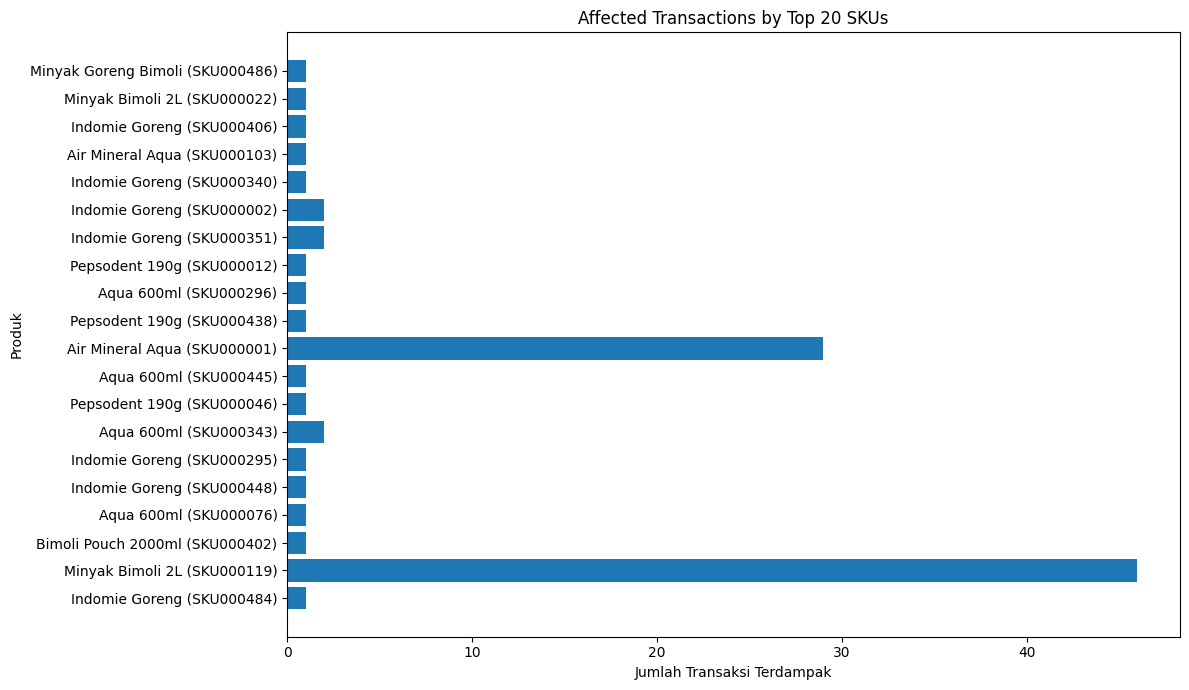

In [55]:

import matplotlib.pyplot as plt

# Mengambil 20 SKU dengan estimasi dampak finansial terbesar
top_sku = sku_evaluation.nlargest(
    20, 'estimated_excess_sales'
).copy()

# Visualisasi frekuensi transaksi terdampak
plt.figure(figsize=(12, 7))

plt.barh(
    top_sku['product_name'] + ' (' + top_sku['sku_id'] + ')',
    top_sku['total_affected_transactions']
)

plt.xlabel('Jumlah Transaksi Terdampak')
plt.ylabel('Produk')
plt.title('Affected Transactions by Top 20 SKUs')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### **8. Pemeriksaan Contoh Transaksi Ekstrem**

Memeriksa detail transaksi dengan quantity sangat tinggi sebagai validasi awal, tanpa menyimpulkan bahwa transaksi tersebut merupakan reselling.

In [56]:

# Memeriksa transaksi terdampak pada dua SKU
selected_sku = ['SKU000119', 'SKU000001']

sku_detail = df_impact[
    (df_impact['sku_id'].isin(selected_sku)) &
    (df_impact['excess_qty'] > 0)
].copy()

sku_detail = sku_detail[
    [
        'receipt_id',
        'trx_time',
        'store_id',
        'sku_id',
        'product_name',
        'member_id',
        'qty',
        'candidate_limit',
        'excess_qty',
        'excess_sales'
    ]
].sort_values(
    ['sku_id', 'qty'],
    ascending=[True, False]
)

display(sku_detail)


,receipt_id,trx_time,store_id,sku_id,product_name,member_id,qty,candidate_limit,excess_qty,excess_sales
553,RCP00019679,2022-08-14 10:00:00+00:00,SAT-0904,SKU000001,Air Mineral Aqua,MEM-44168,2674,79,2595,"31,399,500.00"
550,RCP00302360,2023-05-14 16:00:00+00:00,SAT-0224,SKU000001,Air Mineral Aqua,MEM-23758,89,79,10,"121,000.00"
551,RCP00314771,2025-03-21 14:00:00+00:00,SAT-0915,SKU000001,Air Mineral Aqua,MEM-09041,89,79,10,"121,000.00"
552,RCP00320881,2023-01-01 19:00:00+00:00,SAT-0883,SKU000001,Air Mineral Aqua,MEM-07347,89,79,10,"121,000.00"
544,RCP00314519,2022-10-22 12:00:00+00:00,SAT-0850,SKU000001,Air Mineral Aqua,MEM-36591,88,79,9,"108,900.00"
545,RCP00322122,2023-10-29 00:00:00+00:00,SAT-0503,SKU000001,Air Mineral Aqua,MEM-04727,88,79,9,"108,900.00"
546,RCP00322223,2024-06-21 19:00:00+00:00,SAT-0447,SKU000001,Air Mineral Aqua,MEM-12999,88,79,9,"108,900.00"
547,RCP00335495,2023-11-24 00:00:00+00:00,SAT-0613,SKU000001,Air Mineral Aqua,MEM-09657,88,79,9,"108,900.00"
548,RCP00335658,2022-12-18 00:00:00+00:00,SAT-0758,SKU000001,Air Mineral Aqua,MEM-20721,88,79,9,"108,900.00"
549,RCP00346163,2024-04-06 20:00:00+00:00,SAT-0838,SKU000001,Air Mineral Aqua,MEM-12006,88,79,9,"108,900.00"


In [57]:

# Memeriksa detail transaksi ekstrem Air Mineral Aqua

extreme_transaction = df_merged[
    df_merged['receipt_id'] == 'RCP00019679'
]

display(extreme_transaction.T)


,1093
receipt_id,RCP00019679
store_id,SAT-0904
sku_id,SKU000001
member_id,MEM-44168
trx_time,2022-08-14 10:00:00+00:00
payment_method,Debit BCA
qty,2674
total_price,"22,325,226.00"
transaction_status,COMPLETED
discount_amount,"10,030,174.00"


Transaksi ini memiliki indikasi pembelian dalam jumlah tidak biasa karena pelanggan membeli 2.674 botol Air Mineral Aqua dalam satu transaksi, sedangkan kandidat batas pembelian berdasarkan metode IQR untuk SKU tersebut adalah 79 botol.

In [59]:

# Mengambil seluruh riwayat transaksi pelanggan
member_all_history = df_merged[
    df_merged['member_id'] == 'MEM-44168'
].copy()

# Membuat kolom nama hari
member_all_history['trx_time'] = pd.to_datetime(
    member_all_history['trx_time']
)

member_all_history['day_name'] = (
    member_all_history['trx_time'].dt.day_name()
)

# Mengurutkan transaksi berdasarkan waktu
member_all_history = member_all_history.sort_values('trx_time')

# Menampilkan riwayat transaksi
display(
    member_all_history[
        [
            'receipt_id',
            'trx_time',
            'day_name',
            'store_id',
            'sku_id',
            'product_name',
            'is_jsm_promo',
            'qty',
            'unit_price',
            'total_price'
        ]
    ]
)

# Ringkasan transaksi
print("Jumlah transaksi:",
      member_all_history['receipt_id'].nunique())

print("Total quantity:",
      member_all_history['qty'].sum())

print("Total penjualan: Rp",
      f"{member_all_history['total_price'].sum():,.2f}")

print("\nDistribusi kategori promo:")
print(
    member_all_history['is_jsm_promo']
    .value_counts()
    .rename(index={0: 'Non-JSM', 1: 'JSM'})
)


,receipt_id,trx_time,day_name,store_id,sku_id,product_name,is_jsm_promo,qty,unit_price,total_price
398343,RCP00249682,2022-03-30 15:00:00+00:00,Wednesday,SAT-0892,SKU000441,Rokok Sampoerna Mild,0,2,"20,700.00","41,400.00"
354580,RCP00022333,2022-08-05 08:00:00+00:00,Friday,SAT-0772,SKU000392,Indomie Goreng,0,2,"27,500.00","55,000.00"
1093,RCP00019679,2022-08-14 10:00:00+00:00,Sunday,SAT-0904,SKU000001,Air Mineral Aqua,1,2674,"12,100.00","22,325,226.00"
170073,RCP00222623,2023-01-13 15:00:00+00:00,Friday,SAT-0016,SKU000188,Aqua 600ml,0,2,"10,200.00","20,400.00"
367885,RCP00312477,2025-08-16 07:00:00+00:00,Saturday,SAT-0143,SKU000406,Indomie Goreng,1,77,"42,200.00","1,982,134.00"


Jumlah transaksi: 5
Total quantity: 2757
Total penjualan: Rp 24,424,160.00

Distribusi kategori promo:
is_jsm_promo
Non-JSM    3
JSM        2
Name: count, dtype: Int64


In [64]:
# Menghitung jumlah transaksi berlebih per pelanggan
customer_frequency = (
    df_affected[df_affected['member_id'].notna()]
    .groupby('member_id')
    .agg(
        total_affected_transactions=('receipt_id', 'nunique'),
        total_excess_quantity=('excess_qty', 'sum'),
        estimated_excess_sales=('excess_sales', 'sum')
    )
    .reset_index()
)

# Distribusi frekuensi transaksi berlebih
frequency_distribution = (
    customer_frequency
    .groupby('total_affected_transactions')
    .agg(
        total_customers=('member_id', 'nunique')
    )
    .reset_index()
    .sort_values('total_affected_transactions')
)

display(frequency_distribution)

print("Total pelanggan terdampak:",
      customer_frequency['member_id'].nunique())

print("Pelanggan dengan transaksi berlebih berulang:",
      (customer_frequency['total_affected_transactions'] > 1).sum())

# Mengurutkan pelanggan berdasarkan quantity berlebih
customer_concentration = (
    customer_frequency
    .sort_values(
        'total_excess_quantity',
        ascending=False
    )
    .copy()
)

# Menghitung kontribusi quantity berlebih setiap pelanggan
total_excess = customer_concentration[
    'total_excess_quantity'
].sum()

customer_concentration['contribution_pct'] = (
    customer_concentration['total_excess_quantity']
    / total_excess * 100
)

# Menghitung kontribusi kumulatif
customer_concentration['cumulative_pct'] = (
    customer_concentration['contribution_pct'].cumsum()
)

display(customer_concentration.head(20))

# Kontribusi 10 pelanggan terbesar
top_10_contribution = (
    customer_concentration.head(10)['total_excess_quantity'].sum()
    / total_excess * 100
)

print("Kontribusi 10 pelanggan terbesar:",
      round(top_10_contribution, 2), "%")


,total_affected_transactions,total_customers
0,1,219


Total pelanggan terdampak: 219
Pelanggan dengan transaksi berlebih berulang: 0


,member_id,total_affected_transactions,total_excess_quantity,estimated_excess_sales,contribution_pct,cumulative_pct
213,MEM-47311,1,8039,"72,351,000.00",14.00,14.00
98,MEM-23160,1,7889,"257,181,400.00",13.74,27.74
18,MEM-04143,1,6674,"186,872,000.00",11.62,39.36
97,MEM-22797,1,4927,"21,186,100.00",8.58,47.94
184,MEM-41426,1,4895,"34,265,000.00",8.52,56.46
94,MEM-22019,1,4449,"181,074,300.00",7.75,64.21
123,MEM-28512,1,4437,"166,387,500.00",7.73,71.93
188,MEM-42150,1,3330,"129,870,000.00",5.80,77.73
195,MEM-44168,1,2595,"31,399,500.00",4.52,82.25
79,MEM-18312,1,1504,"6,467,200.00",2.62,84.87


Kontribusi 10 pelanggan terbesar: 84.87 %


Analisis menunjukkan bahwa dari 219 pelanggan yang teridentifikasi memiliki transaksi melebihi kandidat batas pembelian, tidak ditemukan transaksi berlebih yang dilakukan secara berulang oleh pelanggan yang sama. Namun, quantity berlebih terkonsentrasi pada sebagian kecil pelanggan, dengan 10 pelanggan teratas menyumbang 84,87% dari total quantity berlebih kelompok pelanggan teridentifikasi. Temuan ini menunjukkan bahwa dampak pembelian dalam jumlah tidak biasa lebih banyak didominasi oleh sejumlah kecil transaksi ekstrem.

In [63]:

# Mengambil 10 pelanggan dengan quantity berlebih terbesar
top_10_members = customer_concentration.head(10)['member_id']

# Menampilkan detail transaksi mereka
top_10_transactions = (
    df_affected[
        df_affected['member_id'].isin(top_10_members)
    ]
    .sort_values('excess_qty', ascending=False)
)

display(
    top_10_transactions[
        [
            'member_id',
            'receipt_id',
            'trx_time',
            'store_id',
            'sku_id',
            'product_name',
            'qty',
            'candidate_limit',
            'excess_qty',
            'excess_sales'
        ]
    ]
)


,member_id,receipt_id,trx_time,store_id,sku_id,product_name,qty,candidate_limit,excess_qty,excess_sales
39603,MEM-47311,RCP00224382,2023-11-03 09:00:00+00:00,SAT-0445,SKU000351,Indomie Goreng,8145,106,8039,"72,351,000.00"
52721,MEM-23160,RCP00089380,2021-05-30 19:00:00+00:00,SAT-0346,SKU000486,Minyak Goreng Bimoli,7988,99,7889,"257,181,400.00"
12201,MEM-04143,RCP00219768,2023-10-21 19:00:00+00:00,SAT-0939,SKU000103,Air Mineral Aqua,6781,107,6674,"186,872,000.00"
9255,MEM-22797,RCP00000726,2024-02-17 10:00:00+00:00,SAT-0016,SKU000076,Aqua 600ml,5021,94,4927,"21,186,100.00"
45547,MEM-41426,RCP00171355,2025-02-09 18:00:00+00:00,SAT-0284,SKU000438,Pepsodent 190g,4994,99,4895,"34,265,000.00"
3450,MEM-22019,RCP00243571,2021-01-01 12:00:00+00:00,SAT-0769,SKU000022,Minyak Bimoli 2L,4545,96,4449,"181,074,300.00"
36565,MEM-28512,RCP00230713,2022-05-13 08:00:00+00:00,SAT-0641,SKU000340,Indomie Goreng,4536,99,4437,"166,387,500.00"
1130,MEM-42150,RCP00070560,2025-05-09 19:00:00+00:00,SAT-0110,SKU000002,Indomie Goreng,3431,101,3330,"129,870,000.00"
553,MEM-44168,RCP00019679,2022-08-14 10:00:00+00:00,SAT-0904,SKU000001,Air Mineral Aqua,2674,79,2595,"31,399,500.00"
4623,MEM-18312,RCP00169428,2023-01-06 17:00:00+00:00,SAT-0763,SKU000041,Air Mineral Aqua,1592,88,1504,"6,467,200.00"


Temuan ini memperkuat hasil analisis sebelumnya bahwa transaksi dengan quantity berlebih lebih banyak muncul sebagai kejadian ekstrem pada transaksi individual, bukan sebagai pola pembelian berulang oleh pelanggan yang sama.

Namun, kita belum bisa langsung menyimpulkan bahwa transaksi tersebut merupakan praktik reselling. Quantity yang sangat besar juga perlu divalidasi untuk memastikan tidak terdapat kesalahan input pada sistem POS atau perbedaan satuan pencatatan produk.

### **9. Transaction Value Validation**

Memeriksa konsistensi aritmetika antara quantity, harga satuan, diskon, dan total harga.

In [65]:

# 1. Membuat salinan data transaksi JSM
df_validation = df_simulation.copy()

# 2. Menghitung nilai transaksi berdasarkan quantity, harga satuan, dan diskon
df_validation['calculated_total_price'] = (
    df_validation['qty'] * df_validation['unit_price']
) - df_validation['discount_amount']

# 3. Menghitung selisih nilai transaksi
df_validation['price_difference'] = (
    df_validation['total_price'] -
    df_validation['calculated_total_price']
)

# 4. Menentukan kesesuaian perhitungan
df_validation['price_match'] = (
    df_validation['price_difference'].abs() < 0.01
)

# 5. Menampilkan ringkasan validasi
print("Total transaksi yang diperiksa:", len(df_validation))
print(
    "Transaksi dengan perhitungan sesuai:",
    df_validation['price_match'].sum()
)
print(
    "Transaksi dengan perhitungan tidak sesuai:",
    (~df_validation['price_match']).sum()
)
print(
    "Persentase kesesuaian:",
    round(df_validation['price_match'].mean() * 100, 2),
    "%"
)

# 6. Menampilkan 20 transaksi dengan quantity terbesar
display(
    df_validation
    .sort_values('qty', ascending=False)
    [[
        'receipt_id',
        'trx_time',
        'sku_id',
        'product_name',
        'qty',
        'unit_price',
        'discount_amount',
        'total_price',
        'calculated_total_price',
        'price_difference',
        'price_match'
    ]]
    .head(20)
)


Total transaksi yang diperiksa: 54717
Transaksi dengan perhitungan sesuai: 54717
Transaksi dengan perhitungan tidak sesuai: 0
Persentase kesesuaian: 100.0 %


,receipt_id,trx_time,sku_id,product_name,qty,unit_price,discount_amount,total_price,calculated_total_price,price_difference,price_match
318814,RCP00224382,2023-11-03 09:00:00+00:00,SKU000351,Indomie Goreng,8145,"9,000.00","16,127,100.00","57,177,900.00","57,177,900.00",0.00,True
440184,RCP00089380,2021-05-30 19:00:00+00:00,SKU000486,Minyak Goreng Bimoli,7988,"32,600.00","88,538,992.00","171,869,808.00","171,869,808.00",0.00,True
93449,RCP00219768,2023-10-21 19:00:00+00:00,SKU000103,Air Mineral Aqua,6781,"28,000.00","74,048,520.00","115,819,480.00","115,819,480.00",0.00,True
367957,RCP00283870,2021-09-05 18:00:00+00:00,SKU000406,Indomie Goreng,5491,"42,200.00","90,370,878.00","141,349,322.00","141,349,322.00",0.00,True
318813,RCP00203861,2023-06-17 14:00:00+00:00,SKU000351,Indomie Goreng,5088,"9,000.00","10,074,240.00","35,717,760.00","35,717,760.00",0.00,True
11189,RCP00247636,2023-06-11 11:00:00+00:00,SKU000012,Pepsodent 190g,5087,"13,000.00","12,564,890.00","53,566,110.00","53,566,110.00",0.00,True
68806,RCP00000726,2024-02-17 10:00:00+00:00,SKU000076,Aqua 600ml,5021,"4,300.00","8,204,314.00","13,385,986.00","13,385,986.00",0.00,True
395954,RCP00171355,2025-02-09 18:00:00+00:00,SKU000438,Pepsodent 190g,4994,"7,000.00","7,341,180.00","27,616,820.00","27,616,820.00",0.00,True
20272,RCP00243571,2021-01-01 12:00:00+00:00,SKU000022,Minyak Bimoli 2L,4545,"40,700.00","36,996,300.00","147,985,200.00","147,985,200.00",0.00,True
307918,RCP00230713,2022-05-13 08:00:00+00:00,SKU000340,Indomie Goreng,4536,"37,500.00","57,834,000.00","112,266,000.00","112,266,000.00",0.00,True


**Insight — Transaction Value Validation**

Hasil validasi terhadap **54.717 transaksi JSM weekend** menunjukkan bahwa seluruh transaksi memiliki kesesuaian aritmetika antara quantity, harga satuan, diskon, dan total harga. Sebanyak **54.717 transaksi (100%)** memiliki selisih perhitungan kurang dari Rp0,01, sedangkan tidak ditemukan transaksi dengan perhitungan yang tidak sesuai.

Hasil ini menunjukkan bahwa nilai `total_price` pada data transaksi konsisten dengan formula `qty × unit_price − discount_amount` untuk populasi transaksi yang diperiksa. Dengan demikian, `total_price` dapat digunakan sebagai dasar perhitungan nilai penjualan setelah diskon pada analisis lanjutan.

Validasi ini hanya menguji konsistensi aritmetika berdasarkan kolom yang tersedia. Hasil tersebut tidak membuktikan bahwa harga master, persentase diskon, maupun pencatatan transaksi telah sesuai dengan kebijakan komersial yang berlaku.

### **10. Quantity Distribution by SKU and Unit**

Membandingkan median, persentil, dan quantity maksimum untuk memahami karakteristik pembelian setiap SKU dan satuannya.

In [67]:

# Distribusi quantity berdasarkan SKU dan satuan produk

sku_distribution = (
    df_simulation
    .groupby(['sku_id', 'product_name', 'unit_of_measure'])
    .agg(
        total_transactions=('receipt_id', 'nunique'),
        total_quantity=('qty', 'sum'),
        avg_quantity=('qty', 'mean'),
        median_quantity=('qty', 'median'),
        q95=('qty', lambda x: x.quantile(0.95)),
        q99=('qty', lambda x: x.quantile(0.99)),
        max_quantity=('qty', 'max')
    )
    .reset_index()
    .sort_values('max_quantity', ascending=False)
)

display(sku_distribution.head(20))


unit_distribution = (
    df_simulation
    .groupby('unit_of_measure')
    .agg(
        total_sku=('sku_id', 'nunique'),
        total_transactions=('receipt_id', 'nunique'),
        avg_quantity=('qty', 'mean'),
        median_quantity=('qty', 'median'),
        max_quantity=('qty', 'max')
    )
    .reset_index()
    .sort_values('max_quantity', ascending=False)
)

display(unit_distribution)


,sku_id,product_name,unit_of_measure,total_transactions,total_quantity,avg_quantity,median_quantity,q95,q99,max_quantity
66,SKU000351,Indomie Goreng,pack,612,26438,43.20,5.00,81.00,88.00,8145
88,SKU000486,Minyak Goreng Bimoli,pack,611,21486,35.17,4.00,81.50,87.00,7988
20,SKU000103,Air Mineral Aqua,botol,646,21995,34.05,5.00,80.75,88.00,6781
73,SKU000406,Indomie Goreng,pack,613,19152,31.24,5.00,80.00,87.00,5491
3,SKU000012,Pepsodent 190g,pcs,548,17260,31.50,5.00,78.00,87.00,5087
15,SKU000076,Aqua 600ml,botol,582,17549,30.15,4.00,80.00,88.00,5021
76,SKU000438,Pepsodent 190g,pcs,624,18674,29.93,5.00,81.00,87.77,4994
5,SKU000022,Minyak Bimoli 2L,pack,574,16408,28.59,4.00,78.35,88.00,4545
61,SKU000340,Indomie Goreng,pack,595,17490,29.39,4.00,83.00,88.06,4536
1,SKU000002,Indomie Goreng,pack,577,16986,29.44,4.00,78.00,88.00,3431


,unit_of_measure,total_sku,total_transactions,avg_quantity,median_quantity,max_quantity
1,pack,60,34977,22.90,5.00,8145
0,botol,21,12057,23.40,5.00,6781
2,pcs,13,7683,23.41,5.00,5087


**Insight — Quantity Distribution by SKU and Unit**

Distribusi quantity menunjukkan bahwa median pembelian pada ketiga satuan produk, yaitu **pack, botol, dan pcs, sama-sama sebesar 5 unit per transaksi**. Rata-rata quantity berada di kisaran 22,90–23,41 unit, jauh di atas mediannya. Perbedaan ini menunjukkan distribusi quantity yang menceng ke kanan (*right-skewed*), yaitu sebagian kecil transaksi dengan quantity sangat tinggi mendorong nilai rata-rata meningkat.

Satuan pack mencakup 60 SKU dan 34.977 transaksi, botol mencakup 21 SKU dan 12.057 transaksi, sedangkan pcs mencakup 13 SKU dan 7.683 transaksi. Nilai quantity maksimum masing-masing satuan sangat tinggi: **8.145 pack**, **6.781 botol**, dan **5.087 pcs**. Pada tingkat SKU, nilai maksimum juga memperlihatkan transaksi ekstrem, misalnya Indomie Goreng sebanyak 8.145 pack dan Minyak Goreng Bimoli sebanyak 7.988 pack.

Temuan ini mendukung penggunaan median dan persentil selain rata-rata ketika membaca karakteristik pembelian. Namun, perbandingan quantity antar satuan tidak boleh dilakukan secara langsung tanpa mempertimbangkan ukuran kemasan dan definisi satuan jual. Nilai maksimum perlu ditelusuri sebagai transaksi ekstrem, bukan langsung dikategorikan sebagai penyalahgunaan promo.

### **11. Store Impact Analysis**

Mengidentifikasi sebaran gerai yang memiliki transaksi di atas kandidat batas dan mengukur dampaknya.

In [ ]:

# 1. Menghitung total transaksi JSM per gerai
store_baseline = (
    df_simulation
    .groupby(['store_id', 'store_name', 'city'])
    .agg(
        total_jsm_transactions=('receipt_id', 'nunique')
    )
    .reset_index()
)

# 2. Menghitung transaksi quantity berlebih per gerai
store_impact = (
    df_affected
    .groupby(['store_id', 'store_name', 'city'])
    .agg(
        affected_transactions=('receipt_id', 'nunique'),
        affected_sku=('sku_id', 'nunique'),
        total_excess_quantity=('excess_qty', 'sum'),
        estimated_excess_sales=('estimated_net_excess_sales', 'sum'),
        max_quantity=('qty', 'max')
    )
    .reset_index()
)

# 3. Menggabungkan data transaksi normal dan terdampak
store_impact = store_impact.merge(
    store_baseline,
    on=['store_id', 'store_name', 'city'],
    how='left'
)

# 4. Menghitung persentase transaksi terdampak per gerai
store_impact['affected_pct'] = (
    store_impact['affected_transactions'] /
    store_impact['total_jsm_transactions'] * 100
)

# 5. Menghitung kontribusi estimasi penjualan berlebih
store_impact['contribution_pct'] = (
    store_impact['estimated_excess_sales'] /
    store_impact['estimated_excess_sales'].sum() * 100
)

# 6. Mengurutkan berdasarkan quantity berlebih
store_impact = store_impact.sort_values(
    'total_excess_quantity',
    ascending=False
)

display(store_impact.head(20))

print("Total gerai terdampak:", store_impact['store_id'].nunique())
print(
    "Total transaksi terdampak:",
    store_impact['affected_transactions'].sum()
)
print(
    "Total quantity berlebih:",
    store_impact['total_excess_quantity'].sum()
)


top_10_stores = store_impact.head(10).copy()

top_10_stores['store_label'] = (
    top_10_stores['store_name'] + ' (' +
    top_10_stores['city'] + ')'
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_stores['store_label'][::-1],
    top_10_stores['total_excess_quantity'][::-1]
)

plt.title('Top 10 Gerai Berdasarkan Quantity Berlebih')
plt.xlabel('Total Quantity Berlebih')
plt.ylabel('Gerai')
plt.tight_layout()
plt.show()


Analisis menunjukkan bahwa transaksi dengan quantity melebihi kandidat batas pembelian IQR tersebar pada **96 gerai**, dengan total 296 transaksi terdampak dan 76.760 unit quantity berlebih. Gerai Alfamart Pahlawan 345 di Semarang mencatat quantity berlebih tertinggi sebesar 8.997 unit dari 2 transaksi. Hasil ini menunjukkan bahwa transaksi dengan quantity tidak biasa tidak hanya muncul pada satu gerai, sehingga evaluasi operasional perlu dilakukan lintas gerai.

**Catatan:** nilai kontribusi finansial per gerai dihitung menggunakan estimasi nilai penjualan quantity berlebih setelah diskon. Jalankan ulang cell analisis gerai di atas untuk memperbarui tabel dan grafik setelah penyesuaian perhitungan.

### **12. Customer-Level Restriction Policy Simulation**

Bagian ini mengembangkan analisis dari level struk menjadi level **pelanggan × SKU × periode JSM**. Periode dihitung per minggu kalender (Senin–Minggu), sehingga transaksi Jumat, Sabtu, dan Minggu dalam satu akhir pekan dijumlahkan untuk pelanggan dan SKU yang sama.

Kandidat batas dihitung menggunakan IQR dari distribusi quantity agregat pelanggan per SKU per periode JSM. Selanjutnya, beberapa batas ilustratif dibandingkan untuk melihat jumlah kelompok pelanggan-SKU-periode yang terdampak, quantity yang berada di atas batas, dan estimasi diskon yang melekat pada quantity tersebut.

Preseden minyak goreng tahun 2022 dalam project brief menyebut pembatasan maksimal 2 kemasan untuk ukuran 1 liter dan 1 kemasan untuk ukuran 2 liter per pembeli. Angka tersebut merupakan preseden untuk produk dan konteks tertentu, sehingga skenario 2, 5, 10, dan 20 unit di bawah ini hanya digunakan sebagai uji sensitivitas, bukan rekomendasi final yang dapat diterapkan seragam pada seluruh SKU.

In [ ]:
# 1. Menyiapkan transaksi dengan identitas pelanggan
df_customer_policy = df_simulation.copy()
df_customer_policy['trx_time'] = pd.to_datetime(df_customer_policy['trx_time'])

# Periode JSM mingguan: Jumat-Minggu berada pada minggu kalender yang sama
df_customer_policy['jsm_period'] = (
    df_customer_policy['trx_time']
    .dt.to_period('W-SUN')
    .astype(str)
)

# Pisahkan transaksi tanpa member ID karena tidak dapat diagregasikan per pelanggan
df_customer_identified = df_customer_policy.dropna(
    subset=['member_id']
).copy()

df_customer_unidentified = df_customer_policy[
    df_customer_policy['member_id'].isna()
].copy()

# 2. Agregasi quantity dan nilai per pelanggan, SKU, dan periode JSM
customer_sku_period = (
    df_customer_identified
    .groupby([
        'member_id', 'sku_id', 'product_name',
        'category', 'unit_of_measure', 'jsm_period'
    ])
    .agg(
        total_quantity=('qty', 'sum'),
        total_transactions=('receipt_id', 'nunique'),
        total_net_sales=('total_price', 'sum'),
        total_discount=('discount_amount', 'sum')
    )
    .reset_index()
)

# 3. Menentukan kandidat batas IQR pada level pelanggan-SKU-periode
customer_sku_limit = (
    customer_sku_period
    .groupby(['sku_id', 'product_name', 'unit_of_measure'])['total_quantity']
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

customer_sku_limit['IQR'] = (
    customer_sku_limit['Q3'] - customer_sku_limit['Q1']
)

customer_sku_limit['customer_period_upper_bound'] = (
    customer_sku_limit['Q3'] +
    1.5 * customer_sku_limit['IQR']
)

customer_sku_limit['customer_period_candidate_limit'] = (
    np.floor(
        customer_sku_limit['customer_period_upper_bound']
    ).astype(int)
)

customer_sku_period = customer_sku_period.merge(
    customer_sku_limit[
        ['sku_id', 'customer_period_candidate_limit']
    ],
    on='sku_id',
    how='left'
)

# 4. Simulasi batas pembelian ilustratif
policy_scenarios = {
    'Limit 2 unit': 2,
    'Limit 5 unit': 5,
    'Limit 10 unit': 10,
    'Limit 20 unit': 20,
    'IQR customer-SKU-period': 'iqr'
}

policy_results = []

for scenario_name, limit in policy_scenarios.items():
    if limit == 'iqr':
        applicable_limit = customer_sku_period[
            'customer_period_candidate_limit'
        ]
    else:
        applicable_limit = limit

    excess_qty = (
        customer_sku_period['total_quantity'] -
        applicable_limit
    ).clip(lower=0)

    affected_group = excess_qty > 0

    # Alokasi diskon proporsional pada level agregat pelanggan-SKU-periode
    discount_per_unit = (
        customer_sku_period['total_discount'] /
        customer_sku_period['total_quantity'].replace(0, np.nan)
    )
    estimated_excess_discount = excess_qty * discount_per_unit

    policy_results.append({
        'scenario': scenario_name,
        'customer_sku_period_groups': len(customer_sku_period),
        'affected_groups': int(affected_group.sum()),
        'affected_pct': affected_group.mean() * 100,
        'excess_quantity': excess_qty.sum(),
        'estimated_excess_discount': estimated_excess_discount.sum()
    })

policy_comparison = pd.DataFrame(policy_results)
display(policy_comparison.round(2))

# 5. Kelompok pelanggan-SKU-periode yang melampaui kandidat IQR
customer_sku_period['excess_qty_iqr'] = (
    customer_sku_period['total_quantity'] -
    customer_sku_period['customer_period_candidate_limit']
).clip(lower=0)

customer_policy_affected = customer_sku_period[
    customer_sku_period['excess_qty_iqr'] > 0
].copy()

customer_policy_affected = customer_policy_affected.sort_values(
    'excess_qty_iqr',
    ascending=False
)

display(customer_policy_affected.head(20))

print(
    "Jumlah member unik yang dianalisis:",
    df_customer_identified['member_id'].nunique()
)
print(
    "Jumlah kelompok pelanggan-SKU-periode:",
    len(customer_sku_period)
)
print(
    "Jumlah kelompok yang melampaui kandidat IQR:",
    len(customer_policy_affected)
)
print(
    "Transaksi tanpa member ID:",
    df_customer_unidentified['receipt_id'].nunique()
)
print(
    "Quantity transaksi tanpa member ID:",
    df_customer_unidentified['qty'].sum()
)

**Panduan membaca hasil simulasi kebijakan**

- Unit analisis pada bagian ini adalah kelompok pelanggan × SKU × minggu JSM, bukan struk. Satu pelanggan dapat memiliki beberapa kelompok jika membeli SKU atau pada minggu yang berbeda.
- Batas IQR yang dihitung di sini merupakan kandidat batas statistik dari akumulasi pembelian mingguan. Batas tersebut berbeda dari kandidat IQR per struk pada bagian sebelumnya.
- Skenario batas 2, 5, 10, dan 20 unit digunakan untuk menguji sensitivitas. Penerapannya harus mempertimbangkan `unit_of_measure`, ukuran kemasan, karakteristik SKU, serta kebutuhan rumah tangga.
- Transaksi tanpa `member_id` tidak masuk ke simulasi pembatasan per pelanggan. Karena itu, hasil simulasi hanya mencakup pembelian yang dapat diidentifikasi melalui member ID.
- Pembatasan operasional perlu ditetapkan pada level POS dengan mekanisme akumulasi yang jelas. Data historis ini belum dapat membuktikan bahwa pelanggan yang melewati batas adalah reseller atau melakukan penyalahgunaan promo.

# **Penutup**
## **Kesimpulan**

Berdasarkan analisis terhadap 54.717 transaksi Promo JSM pada hari Jumat–Minggu dengan status transaksi COMPLETED dan quantity positif, ditemukan 296 transaksi atau sekitar 0,54% yang memiliki kuantitas pembelian melebihi kandidat batas berdasarkan metode IQR per SKU.

Dari transaksi tersebut, total quantity berlebih mencapai 76.760 unit dengan estimasi nilai penjualan setelah diskon sebesar **Rp1.175.916.383**, atau sekitar **5,54% dari total penjualan JSM weekend**.

Beberapa temuan utama dari analisis adalah:

1. **Konsentrasi produk:** Kategori Food & Staples menyumbang 72,18% dari estimasi nilai penjualan quantity berlebih, diikuti Beverage sebesar 18,87% dan Personal Care sebesar 8,95%.
2. **Pola pelanggan:** Terdapat 219 pelanggan teridentifikasi pada transaksi terdampak. Tidak ditemukan pelanggan dengan transaksi berlebih berulang berdasarkan hasil identifikasi member ID. Sebanyak 77 transaksi terdampak tidak memiliki member ID.
3. **Pola waktu:** Sebagian besar interval transaksi antar pelanggan yang berhasil dianalisis berada di atas 30 hari, sehingga belum ditemukan indikasi kuat pembelian berlebih yang dilakukan secara berulang dalam waktu berdekatan.
4. **Distribusi gerai:** Transaksi terdampak tersebar di 96 gerai. Gerai Alfamart Pahlawan 345 di Semarang memiliki total quantity berlebih tertinggi, yaitu 8.997 unit.

Secara keseluruhan, temuan ini menunjukkan adanya sejumlah transaksi dengan kuantitas pembelian yang sangat tinggi dan berpotensi memerlukan pengawasan lebih lanjut. Namun, pola tersebut belum dapat membuktikan adanya praktik reselling atau penyalahgunaan promo. Estimasi nilai penjualan quantity berlebih juga tidak dapat langsung dianggap sebagai kerugian margin aktual.

## **Rekomendasi**

Berdasarkan hasil analisis, beberapa rekomendasi yang dapat dipertimbangkan oleh manajemen Alfamart adalah:

1. **Memprioritaskan pengawasan kategori Food & Staples.** Kategori ini menyumbang estimasi penjualan quantity berlebih sebesar Rp848.758.461 atau 72,18% dari total dampak. Tiga SKU dengan estimasi penjualan quantity berlebih tertinggi adalah:
   - Minyak Goreng Bimoli (SKU000486): Rp169.739.724.
   - Minyak Bimoli 2L (SKU000022): Rp144.859.440.
   - Indomie Goreng (SKU000406): Rp138.672.154.

   Ketiga SKU tersebut menyumbang sekitar Rp453,27 juta atau 53,4% dari estimasi dampak kategori Food & Staples. Oleh karena itu, produk-produk tersebut dapat menjadi prioritas awal dalam evaluasi dan penerapan pembatasan kuantitas.

2. **Mengevaluasi batas pembelian berdasarkan karakteristik SKU.** Menggunakan hasil perhitungan IQR sebagai kandidat batas pembelian awal, kemudian memvalidasinya dengan kebutuhan pembelian konsumen, satuan produk, serta kewajaran kuantitas transaksi sebelum menetapkan batas final.

3. **Meningkatkan pengawasan gerai dengan transaksi berlebih.** Memprioritaskan 96 gerai yang teridentifikasi memiliki transaksi terdampak. Salah satu prioritas pemeriksaan adalah Alfamart Pahlawan 345 di Semarang, dengan total quantity berlebih sebesar 8.997 unit, tertinggi di antara gerai yang dianalisis.

4. **Memperkuat identifikasi dan pemantauan pelanggan.** Dari 296 transaksi terdampak, terdapat 219 pelanggan yang teridentifikasi melalui member ID, sementara 77 transaksi tidak memiliki member ID. Alfamart dapat meningkatkan penggunaan identifikasi pelanggan untuk membantu pemantauan pola pembelian dan mendeteksi transaksi berlebih yang berulang.

5. **Melakukan monitoring dan evaluasi berkala.** Memantau perubahan jumlah transaksi terdampak, quantity berlebih, dan estimasi nilai penjualannya setelah kebijakan pembatasan diterapkan. Evaluasi dilakukan untuk memastikan kebijakan tetap efektif tanpa menghambat pembelian wajar oleh konsumen.